# School Nonattendance in Nigeria: MICS 2021

## Problem statement

School nonattendance limits children’s access to educational opportunities. Understanding the household and demographic circumstances associated with nonattendance can inform efforts to promote inclusive education. However, identifying nonattending children reliably from these characteristics remains a challenge.

## Mission

Promote inclusive education by understanding patterns associated with nonattendance and informing where further investigation and educational support may be needed.


## Prediction target

**0 = attended; 1 = did not attend** school or an early-childhood programme during the current school year. The task classifies reported attendance; it does not predict future dropout or establish causes.


## 1. Google Colab setup

Use a Python CPU runtime. The input cell imports the dataset from its Google Drive file link. Each experiment displays its results here and logs them to TensorBoard. No TensorBoard account, API key or result download is needed to view the figures.


### Install dependencies

The cell below installs pinned packages. After it finishes, restart the session once, then continue from the input cell so the installed versions are used.


In [36]:
%pip install -q "numpy==2.1.3" "pandas==2.2.3" "pyreadstat==1.3.6" "scikit-learn==1.6.1" "matplotlib==3.10.0" "joblib==1.6.0" "tensorflow==2.21.0" "tensorboard==2.20.0"


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 57.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.9/572.9 MB 3.4 MB/s eta 0:00:00


### Load the input from Google Drive

Your file link is already entered below. Run the cell and sign in with the Google account that can access it. The cell copies the ZIP or SAV into Colab and checks the transfer size; no mounted path or manual upload is needed. [Colab Drive guide](https://colab.research.google.com/notebooks/io.ipynb).


In [2]:
from pathlib import Path
from datetime import datetime, timezone
from google.colab import auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload
import re
import uuid

DRIVE_LINK = 'https://drive.google.com/file/d/1a1mH3YSxAxGWKWs9sHXtvieoS1yTBAaF/view?usp=drive_link'
match = re.search(r'/file/d/([^/]+)', DRIVE_LINK)
assert match, 'Provide the sharing link for the dataset ZIP or fs.sav file.'
file_id = match.group(1)

auth.authenticate_user()  # Sign in with the Google account that can access this file.
drive_service = build('drive', 'v3', cache_discovery=False)
file_info = drive_service.files().get(
    fileId=file_id, fields='name,mimeType,size', supportsAllDrives=True
).execute()
assert file_info['mimeType'] != 'application/vnd.google-apps.folder', 'Select the ZIP or fs.sav file inside the folder.'
file_name = Path(file_info['name']).name
assert Path(file_name).suffix.lower() in ['.zip', '.sav'], f'Expected a ZIP or SAV dataset; found: {file_name}'

SESSION_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S') + '-' + uuid.uuid4().hex[:8]
WORK = Path('/content/mics_project') / SESSION_ID
input_dir = WORK / 'input'
input_dir.mkdir(parents=True, exist_ok=True)
INPUT_PATH = input_dir / file_name
partial_path = input_dir / (file_name + '.part')

request = drive_service.files().get_media(fileId=file_id, supportsAllDrives=True)
with partial_path.open('wb') as destination:
    downloader = MediaIoBaseDownload(destination, request, chunksize=8 * 1024 * 1024)
    done = False
    while not done:
        progress, done = downloader.next_chunk(num_retries=3)
        if progress:
            print(f'Importing from Drive: {progress.progress():.0%}')

if 'size' in file_info:
    assert partial_path.stat().st_size == int(file_info['size']), 'Incomplete transfer; rerun this cell.'
partial_path.replace(INPUT_PATH)
print('Using:', INPUT_PATH.name)


Importing from Drive: 32%
Importing from Drive: 65%
Importing from Drive: 97%
Importing from Drive: 100%
Using: NGA_2021_MICS6_v01_M.zip


## 2. Imports and reproducibility

The cell below imports packages, sets the random seed and records library versions. Matching seeds, data and versions supports reproducibility.


In [3]:
from pathlib import Path
import io, json, zipfile, hashlib, platform, importlib.metadata, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyreadstat
import joblib
from IPython.display import display, Markdown
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_colwidth', 90)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
WORK.mkdir(parents=True, exist_ok=True)
ARTIFACTS = WORK / 'preprocessing_artifacts'
ARTIFACTS.mkdir(exist_ok=True)
versions = {p: importlib.metadata.version(p) for p in
            ['numpy','pandas','pyreadstat','scikit-learn','matplotlib','joblib']}
display(pd.Series(versions, name='version').to_frame())


,version
numpy,2.1.3
pandas,2.3.3
pyreadstat,1.3.6
scikit-learn,1.6.1
matplotlib,3.10.0
joblib,1.6.0


## 3. Load the data and dictionary

The cell below reads only `fs.sav`, preserves SPSS labels and records the file fingerprint. It checks the raw size before exclusions; no survey-table merge is required.

Data source: [Nigeria MICS 2021 survey catalogue](https://microdata.worldbank.org/catalog/5959).


In [4]:
def find_sav(payload, label, depth=0):
    if depth > 4:
        raise ValueError('Archive nesting exceeds expected depth.')
    if label.lower().endswith('.sav'):
        return [(label, payload)] if Path(label).name.lower() == 'fs.sav' else []
    hits = []
    with zipfile.ZipFile(io.BytesIO(payload)) as archive:
        for member in archive.infolist():
            name = member.filename
            if member.is_dir():
                continue
            if 'readme' in Path(name).name.lower():
                (WORK / ('source_readme' + Path(name).suffix)).write_bytes(archive.read(member))
            if name.lower().endswith('.zip') or Path(name).name.lower() == 'fs.sav':
                hits += find_sav(archive.read(member), label + ' :: ' + name, depth+1)
    return hits

payload = INPUT_PATH.read_bytes()
hits = find_sav(payload, INPUT_PATH.name)
assert len(hits) == 1, f'Expected one fs.sav, found {len(hits)}; select a specific input.'
source_member, sav_bytes = hits[0]
sav_path = WORK / 'fs.sav'
sav_path.write_bytes(sav_bytes)
raw, meta = pyreadstat.read_sav(str(sav_path), apply_value_formats=False, user_missing=True)
# SPSS names may be lower-case in another export; preserve a consistent schema.
raw.columns = raw.columns.str.upper()
labels = {k.upper(): v for k,v in meta.column_names_to_labels.items()}
value_labels = {k.upper(): v for k,v in meta.variable_value_labels.items()}
missing_ranges = {k.upper(): v for k,v in meta.missing_ranges.items()}
source_hash = hashlib.sha256(sav_bytes).hexdigest()
print('Archive member:', source_member)
print('Raw shape:', raw.shape, '| SHA-256:', source_hash)
assert len(raw) >= 20000, 'Dataset does not meet the assignment raw-row minimum.'
assert raw.shape == (22706, 427), 'Unexpected release: review the schema before continuing.'
dictionary = pd.DataFrame({
    'variable': raw.columns,
    'description': [labels.get(c,'') for c in raw],
    'dtype': [str(raw[c].dtype) for c in raw],
    'system_missing_pct': [raw[c].isna().mean()*100 for c in raw],
    'distinct_observed': [raw[c].nunique() for c in raw],
    'value_labels': [json.dumps(value_labels.get(c,{}),ensure_ascii=False) for c in raw],
})
display(dictionary.head(12))
dictionary.to_csv(ARTIFACTS / 'data_dictionary.csv', index=False)


Archive member: NGA_2021_MICS6_v01_M.zip :: NGA_2021_MICS6_v01_M/NGA_2021_MICS6_Datasets/Nigeria MICS6 SPSS Datasets.zip :: Nigeria MICS6 SPSS Datasets/fs.sav
Raw shape: (22706, 427) | SHA-256: 6e5283706128255d4393db19ef397d41a9116d20ad94db1bc42351ca7f566ae4


,variable,description,dtype,system_missing_pct,distinct_observed,value_labels
0,HH1,Cluster number,float64,0.0,1755,{}
1,HH2,Household number,float64,0.0,21,{}
2,LN,Line number,float64,0.0,22,{}
3,FS1,Cluster number,float64,0.0,1755,{}
4,FS2,Household number,float64,0.0,21,{}
5,FS3,Child's line number,float64,0.0,22,{}
6,FSINT,Interviewer number,float64,0.0,298,{}
7,FS4,Mother / Caretaker's line number,float64,0.0,20,{}
8,FS5,Interviewer number,float64,0.0,298,{}
9,FS6,Supervisor number,float64,0.0,74,{}


## 4. Audit identifiers and attendance responses

The cell below checks duplicate child records and compares lifetime attendance (`CB4`) with current-year attendance (`CB7`). Missing values and explicit response codes are inspected separately.


In [5]:
required = ['HH1','HH2','LN','FS17','CB3','CB4','CB7','HL4','HH6','HH7',
            'HH52','MELEVEL','WINDEX5','FSWEIGHT','PSU']
assert set(required).issubset(raw.columns), set(required)-set(raw.columns)
def frequency_table(column):
    s = raw[column].value_counts(dropna=False).rename_axis('code').reset_index(name='rows')
    s['meaning'] = s['code'].map(value_labels.get(column,{})).fillna('System-missing/unlabelled')
    return s
for column in ['FS17','CB4','CB7']:
    print(column, labels[column]); display(frequency_table(column))
display(pd.crosstab(raw['CB4'].fillna(-1), raw['CB7'].fillna(-1),
                    rownames=['CB4 (-1 = system missing)'], colnames=['CB7 (-1 = system missing)']))
key = ['HH1','HH2','LN']
print('Duplicate child IDs:', int(raw.duplicated(key).sum()))
print('Completely duplicated rows:', int(raw.duplicated().sum()))
assert not raw[key].isna().any().any(), 'Missing identifiers require manual review.'
assert not raw.duplicated(key).any(), 'Duplicate identifiers require investigation, not automatic deletion.'


FS17 Result of interview for children 5-17


,code,rows,meaning
0,1.0,22443,COMPLETED
1,2.0,204,NOT AT HOME
2,6.0,21,NO ADULT CONSENT FOR MOTHER / CARETAKER AGE 15-17
3,5.0,18,INCAPACITATED
4,4.0,11,PARTLY COMPLETED
5,3.0,7,REFUSED
6,96.0,2,OTHER


CB4 Ever attended school or early childhood programme


,code,rows,meaning
0,1.0,18009,YES
1,2.0,4436,NO
2,NaN,252,System-missing/unlabelled
3,9.0,9,NO RESPONSE


CB7 Attended school or early childhood programme during current school year


,code,rows,meaning
0,1.0,16438,YES
1,NaN,4697,System-missing/unlabelled
2,2.0,1569,NO
3,9.0,2,NO RESPONSE


CB7 (-1 = system missing),-1.0,1.0,2.0,9.0
CB4 (-1 = system missing),,,,
-1.0,252,0,0,0
1.0,0,16438,1569,2
2.0,4436,0,0,0
9.0,9,0,0,0


Duplicate child IDs: 0
Completely duplicated rows: 0


## 5. Define the cohort and target

The cell below keeps completed interviews for ages 5–17 and constructs the binary target. Nonattendance is reconstructed only when `CB4=2` explicitly means “never attended” and `CB7` is system-missing. Unresolved or contradictory labels are excluded.


In [6]:
completed = raw['FS17'].eq(1)
valid_age = raw['CB3'].between(5,17) & raw['CB3'].mod(1).eq(0)
contradiction = raw['CB4'].eq(2) & raw['CB7'].eq(1)
target = raw['CB7'].map({1:0, 2:1}).astype('Float64')
derived = raw['CB4'].eq(2) & raw['CB7'].isna()
target.loc[derived] = 1
reason = pd.Series('included', index=raw.index)
reason.loc[target.isna()] = 'unknown target'
reason.loc[contradiction] = 'contradictory attendance answers'
reason.loc[~valid_age] = 'missing/invalid age'
reason.loc[~completed] = 'interview not completed'
flow = reason.value_counts().rename_axis('disposition').reset_index(name='rows')
assert flow['rows'].sum() == len(raw)
display(flow)
keep = reason.eq('included')
cohort = raw.loc[keep].copy()
cohort['nonattendance'] = target.loc[keep].astype('int8')
cohort['target_origin'] = np.where(derived.loc[keep], 'derived: never attended', 'direct CB7')
display(pd.crosstab(cohort['target_origin'], cohort['nonattendance']))
print('Raw:',len(raw),'| Eligible:',len(cohort),'| Removed:',len(raw)-len(cohort))
assert set(cohort['nonattendance'].unique()) == {0,1}
flow.to_csv(ARTIFACTS/'cohort_flow.csv',index=False)


,disposition,rows
0,included,22432
1,interview not completed,263
2,unknown target,11


nonattendance,0,1
target_origin,,
derived: never attended,0,4435
direct CB7,16428,1569


Raw: 22706 | Eligible: 22432 | Removed: 274


## 6. Select and clean predictors

The cell below retains age, household child count, sex, area, state, maternal education and wealth. It cleans field-specific missing codes and excludes attendance history, learning outcomes and identifiers to limit leakage.


In [7]:
numeric = ['CB3','HH52']
categorical = ['HL4','HH6','HH7','MELEVEL','WINDEX5']
features = numeric + categorical
feature_notes = {
 'CB3':'Age; valid range 5–17', 'HH52':'Number of children aged 5–17 in household',
 'HL4':'Sex; categorical', 'HH6':'Urban/rural area; categorical',
 'HH7':'State/region; categorical, not a numeric scale',
 'MELEVEL':"Mother’s education; categorical, preserve substantive categories",
 'WINDEX5':'Wealth quintile; categorical to avoid assuming equal distances'}
feature_manifest = pd.DataFrame([
 {'variable':c,'description':labels[c],'role':'numeric' if c in numeric else 'categorical',
  'rationale':feature_notes[c],'codes':str(value_labels.get(c,{}))} for c in features])
display(feature_manifest)
feature_manifest.to_csv(ARTIFACTS/'feature_manifest.csv',index=False)

def clean_feature(series, column):
    s = pd.to_numeric(series,errors='coerce').astype(float)
    for item in missing_ranges.get(column,[]):
        s = s.mask(s.between(item['lo'],item['hi']))
    # Labels are specific to each variable: no global numeric missing-value rule.
    invalid_codes = [k for k,v in value_labels.get(column,{}).items()
                     if re.search(r"no response|missing|don.?t know|not stated|refus", str(v),re.I)]
    return s.mask(s.isin(invalid_codes))

X = pd.DataFrame({c:clean_feature(cohort[c],c) for c in features},index=cohort.index)
invalid_hh52 = (X['HH52'] < 1) | X['HH52'].mod(1).ne(0)
X.loc[invalid_hh52,'HH52'] = np.nan
for c in categorical:
    allowed = set(value_labels.get(c,{}))
    assert allowed, f'No response-label dictionary for {c}'
    unexpected = set(X[c].dropna().unique()) - allowed
    assert not unexpected, f'Unlabelled codes for {c}: {unexpected}; review before continuing.'
    # Strings prevent accidental ordinal interpretation of nominal codes.
    X[c] = X[c].map(lambda v: str(int(v)) if pd.notna(v) else np.nan)
y = cohort['nonattendance']
print('Invalid household-child counts changed to missing:',int(invalid_hh52.sum()))
display(X.isna().sum().rename('missing after cleaning').to_frame())
assert not set(features) & {'CB4','CB7','FS17','PSU','FSWEIGHT','HH1','HH2','LN'}


,variable,description,role,rationale,codes
0,CB3,Age of child,numeric,Age; valid range 5–17,{}
1,HH52,Number of children age 5-17,numeric,Number of children aged 5–17 in household,{}
2,HL4,Sex,categorical,Sex; categorical,"{1.0: 'MALE', 2.0: 'FEMALE'}"
3,HH6,Area,categorical,Urban/rural area; categorical,"{1.0: 'URBAN', 2.0: 'RURAL'}"
4,HH7,Region,categorical,"State/region; categorical, not a numeric scale","{1.0: 'ABIA', 2.0: 'ADAMAWA', 3.0: 'AKWA IBOM', 4.0: 'ANAMBRA', 5.0: 'BAUCHI', 6.0: 'B..."
5,MELEVEL,Mother's education,categorical,"Mother’s education; categorical, preserve substantive categories","{0.0: 'None', 1.0: 'Primary', 2.0: 'Junior secondary', 3.0: 'Senior secondary', 4.0: '..."
6,WINDEX5,Wealth index quintile - MICS,categorical,Wealth quintile; categorical to avoid assuming equal distances,"{1.0: 'Poorest', 2.0: 'Second', 3.0: 'Middle', 4.0: 'Fourth', 5.0: 'Richest'}"


Invalid household-child counts changed to missing: 0


,missing after cleaning
CB3,0
HH52,0
HL4,0
HH6,0
HH7,0
MELEVEL,206
WINDEX5,0


## 7. Split by survey community

The cell below assigns entire PSUs to training, validation or testing, preventing cluster overlap. Training fits models, validation supports selection, and the optional test evaluation remains disabled.


In [8]:
assert cohort['PSU'].notna().all(), 'Missing cluster identifiers must be resolved.'
groups = cohort['PSU'].astype(int).astype(str)
outer = StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED)
dev_pos,test_pos = next(outer.split(X,y,groups))
inner = StratifiedGroupKFold(n_splits=4,shuffle=True,random_state=SEED)
train_rel,val_rel = next(inner.split(X.iloc[dev_pos],y.iloc[dev_pos],groups.iloc[dev_pos]))
positions = {'train':dev_pos[train_rel],'validation':dev_pos[val_rel],'test':test_pos}
parts = {name:(X.iloc[pos].copy(),y.iloc[pos].copy()) for name,pos in positions.items()}
group_sets = {name:set(groups.iloc[pos]) for name,pos in positions.items()}
assert not group_sets['train'] & group_sets['validation']
assert not group_sets['train'] & group_sets['test']
assert not group_sets['validation'] & group_sets['test']
assert len(set(np.concatenate(list(positions.values())))) == len(cohort)
split_summary = pd.DataFrame([
 {'split':name,'rows':len(pos),'clusters':len(group_sets[name]),
  'nonattendance_n':int(y.iloc[pos].sum()),'nonattendance_pct':y.iloc[pos].mean()*100}
 for name,pos in positions.items()])
display(split_summary)
for _,ys in parts.values(): assert ys.nunique()==2
X_train,y_train = parts['train']
train_cohort = cohort.loc[X_train.index]
split_summary.to_csv(ARTIFACTS/'split_summary.csv',index=False)


,split,rows,clusters,nonattendance_n,nonattendance_pct
0,train,13444,1046,3536,26.301696
1,validation,4446,351,1183,26.608187
2,test,4542,358,1285,28.291502


## 8. Explore training data

The cell below plots class balance and numeric distributions, checks missingness and flags unusual household counts. Repeated feature profiles are distinguished from duplicate children.


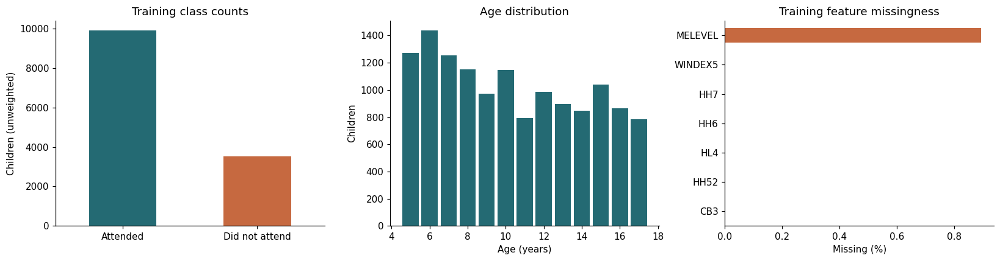

,count,mean,std,min,1%,25%,50%,75%,99%,max
CB3,13444.0,10.412898,3.772278,5.0,5.0,7.0,10.0,14.0,17.0,17.0
HH52,13444.0,2.806754,1.864684,1.0,1.0,1.0,2.0,4.0,9.0,18.0


HH52 values above an exploratory IQR fence (retained): 201
Majority-class share, training only: 0.737
Repeated feature profiles (not duplicate children): 1746


In [9]:
fig,axes = plt.subplots(1,3,figsize=(15,4))
y_train.value_counts().reindex([0,1]).set_axis(['Attended','Did not attend']).plot.bar(
    ax=axes[0],color=['#246a73','#c66940'],rot=0,title='Training class counts')
axes[0].set_ylabel('Children (unweighted)')
X_train['CB3'].plot.hist(ax=axes[1],bins=np.arange(4.5,18.5,1),color='#246a73',rwidth=.85)
axes[1].set(title='Age distribution',xlabel='Age (years)',ylabel='Children')
(X_train.isna().mean()*100).sort_values().plot.barh(ax=axes[2],color='#c66940')
axes[2].set(title='Training feature missingness',xlabel='Missing (%)')
fig.tight_layout(); fig.savefig(ARTIFACTS/'01_training_overview.png',bbox_inches='tight'); plt.show()
display(X_train[numeric].describe(percentiles=[.01,.25,.5,.75,.99]).T)
q1,q3 = X_train['HH52'].quantile([.25,.75]); upper = q3+1.5*(q3-q1)
print('HH52 values above an exploratory IQR fence (retained):',int(X_train['HH52'].gt(upper).sum()))
print('Majority-class share, training only:',round(y_train.value_counts(normalize=True).max(),4))
print('Repeated feature profiles (not duplicate children):',int(X_train.duplicated().sum()))


## 9. Compare groups and survey weights

The cell below summarizes training nonattendance by sex, area, wealth and maternal education, then compares weighted and unweighted prevalence. These are descriptive associations, not causal effects.


,n,rate
group,,
MALE,6738,0.250519
FEMALE,6706,0.275574


,n,rate
group,,
URBAN,4084,0.133448
RURAL,9360,0.319551


,n,rate
group,,
Richest,1804,0.072616
Fourth,2459,0.102887
Middle,2941,0.165250
Second,3056,0.313482
Poorest,3184,0.536432


,n,rate
group,,
Higher/tertiary,1374,0.063319
Senior secondary,2959,0.080095
Junior secondary,867,0.104960
Primary,2864,0.135824
None,5260,0.499620
Missing,120,0.866667


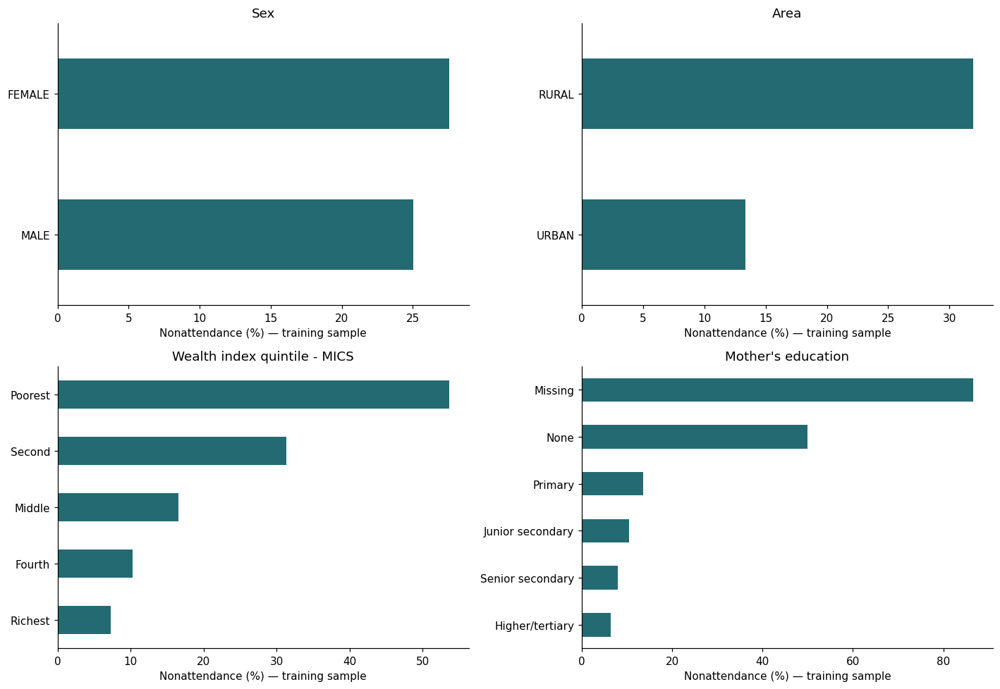

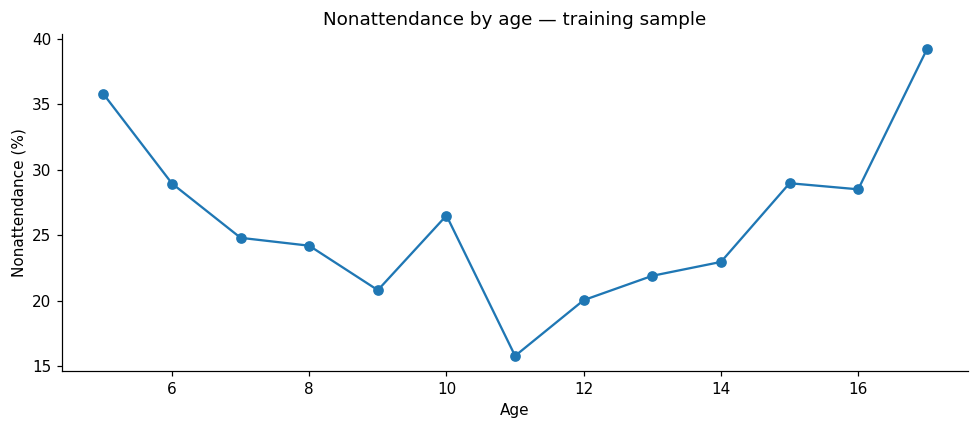

Training unweighted nonattendance: 0.263
Training weighted nonattendance, valid weights only: 0.265
Rows excluded from weighted descriptive estimate: 0


In [10]:
def group_rates(column):
    t = pd.DataFrame({'group':X_train[column].fillna('Missing').astype(str),
                      'nonattendance':y_train})
    result = t.groupby('group')['nonattendance'].agg(n='size',rate='mean')
    if column in categorical:
        mapping = {str(int(k)):v for k,v in value_labels[column].items()}
        result.index = result.index.map(lambda v:mapping.get(v,v))
    return result.sort_values('rate')

fig,axes = plt.subplots(2,2,figsize=(13,9))
for column,ax in zip(['HL4','HH6','WINDEX5','MELEVEL'],axes.flat):
    rates = group_rates(column)
    (rates['rate']*100).plot.barh(ax=ax,color='#246a73')
    ax.set(title=labels[column],xlabel='Nonattendance (%) — training sample',ylabel='')
    display(rates)
fig.tight_layout(); fig.savefig(ARTIFACTS/'02_training_group_rates.png',bbox_inches='tight'); plt.show()
age_rates = pd.DataFrame({'age':X_train['CB3'],'target':y_train}).groupby('age')['target'].agg(['size','mean'])
ax = (age_rates['mean']*100).plot(marker='o',title='Nonattendance by age — training sample')
ax.set(xlabel='Age',ylabel='Nonattendance (%)'); plt.tight_layout()
plt.savefig(ARTIFACTS/'03_age_rates.png',bbox_inches='tight'); plt.show()
weights = pd.to_numeric(train_cohort['FSWEIGHT'],errors='coerce')
weight_ok = weights.notna() & np.isfinite(weights) & weights.gt(0)
assert weight_ok.any()
print('Training unweighted nonattendance:',round(y_train.mean(),4))
print('Training weighted nonattendance, valid weights only:',
      round(np.average(y_train.loc[weight_ok],weights=weights.loc[weight_ok]),4))
print('Rows excluded from weighted descriptive estimate:',int((~weight_ok).sum()))


## 10. Fit preprocessing and engineer features

The cell below fits imputation, scaling and one-hot encoding on training data. Enhanced inputs add age bands and log-transformed household child count. Classical CV later refits preprocessing within each fold.


In [11]:
def add_features(frame):
    out = frame.copy()
    out['age_band'] = pd.cut(out['CB3'],bins=[4,9,14,17],labels=['5–9','10–14','15–17']).astype(object)
    out['log_children_5_17'] = np.log1p(out['HH52'])
    return out

def make_preprocessor(num_columns,cat_columns):
    return ColumnTransformer([
        ('numeric',Pipeline([
            ('imputer',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),
            ('scale',StandardScaler())]),num_columns),
        ('categorical',Pipeline([
            ('imputer',SimpleImputer(strategy='constant',fill_value='Missing',keep_empty_features=True)),
            ('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False,dtype=np.float32))]),cat_columns)
    ],remainder='drop',verbose_feature_names_out=True)

representations = {}
for variant in ['baseline','enhanced']:
    frames = {name:(add_features(frame) if variant=='enhanced' else frame.copy())
              for name,(frame,_) in parts.items()}
    num = numeric + (['log_children_5_17'] if variant=='enhanced' else [])
    cat = categorical + (['age_band'] if variant=='enhanced' else [])
    preprocessor = make_preprocessor(num,cat)
    preprocessor.fit(frames['train'])
    matrices = {name:preprocessor.transform(frame).astype(np.float32) for name,frame in frames.items()}
    names = preprocessor.get_feature_names_out()
    for name,array in matrices.items():
        assert np.isfinite(array).all(), f'{variant}/{name} contains non-finite values'
        assert array.shape == (len(parts[name][1]),len(names))
    representations[variant] = {'preprocessor':preprocessor,'matrices':matrices,
                                 'feature_names':names,'frames':frames}
    print(variant, {name:array.shape for name,array in matrices.items()})
    joblib.dump(preprocessor,ARTIFACTS/f'{variant}_preprocessor.joblib')
    pd.Series(names,name='transformed_feature').to_csv(ARTIFACTS/f'{variant}_feature_names.csv',index=False)


baseline {'train': (13444, 54), 'validation': (4446, 54), 'test': (4542, 54)}
enhanced {'train': (13444, 58), 'validation': (4446, 58), 'test': (4542, 58)}


### Save the preparation audit

The cell below records the data fingerprint, cohort rules, feature definitions and split checks. Export of private record-level arrays stays disabled.


In [12]:
EXPORT_PRIVATE_ARRAYS = False
audit = {
 'source':'UNICEF/NBS Nigeria MICS 2021, fs.sav',
 'source_catalog':'https://microdata.worldbank.org/catalog/5959',
 'source_member':source_member, 'fs_sav_sha256':source_hash,
 'raw_shape':list(raw.shape),'eligible_rows':len(cohort),'seed':SEED,
 'target':{'0':'attended','1':'did not attend'},
 'derived_target_rule':'CB4=2 and CB7 system missing => nonattendance',
 'target_origins':cohort['target_origin'].value_counts().to_dict(),
 'features':features,'group_variable':'PSU','versions':versions,
 'python':platform.python_version(), 'split_summary':split_summary.to_dict(orient='records'),
 'stage':'EDA and preprocessing only; no classifier trained'
}
(ARTIFACTS/'audit.json').write_text(json.dumps(audit,indent=2),encoding='utf-8')
(ARTIFACTS/'requirements-tested.txt').write_text(chr(10).join(f'{p}=={v}' for p,v in versions.items())+chr(10))
if EXPORT_PRIVATE_ARRAYS:
    private_dir = WORK/'PRIVATE_DO_NOT_COMMIT'; private_dir.mkdir(exist_ok=True)
    for variant,result in representations.items():
        for split,array in result['matrices'].items():
            idx = parts[split][0].index
            np.savez_compressed(private_dir/f'{variant}_{split}.npz', X=array,
                y=parts[split][1].to_numpy(dtype=np.int32),
                row_index=idx.to_numpy(), group=cohort.loc[idx,'PSU'].to_numpy(),
                sample_weight=cohort.loc[idx,'FSWEIGHT'].to_numpy(),
                target_direct=cohort.loc[idx,'target_origin'].eq('direct CB7').to_numpy())
print('PASS: raw threshold; schema; unique child IDs; two classes; disjoint clusters; finite transformed arrays.')
print('Artifacts:',ARTIFACTS)
print('No predictive model has been trained and no prediction metrics have been claimed.')


PASS: raw threshold; schema; unique child IDs; two classes; disjoint clusters; finite transformed arrays.
Artifacts: /content/mics_project/20261017T214243-e13712d9/preprocessing_artifacts
No predictive model has been trained and no prediction metrics have been claimed.


## 11. Initialize TensorBoard

The cell below records metrics, figures and settings separately for each run. Consistent metric names allow TensorBoard to overlay curves; the HParams table compares completed experiments.


In [13]:
import os
import uuid
from datetime import datetime, timezone
from numbers import Real
from matplotlib.figure import Figure
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
import tensorflow as tf

tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
versions['tensorflow'] = tf.__version__
versions['tensorboard'] = importlib.metadata.version('tensorboard')
TENSORBOARD_ROOT = WORK/'tensorboard'
RESULTS = WORK/'results'
MODEL_DIR = WORK/'models'
for folder in [TENSORBOARD_ROOT, RESULTS, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

from tensorboard.plugins.hparams import api as hp
HPARAM_NAMES = ['experiment','model','features','C','n_estimators','max_depth','min_samples_leaf',
                'max_features','learning_rate','max_leaf_nodes','l2_regularization',
                'hidden_units','dropout','l2','batch_size','max_epochs']
schema_writer = tf.summary.create_file_writer(str(TENSORBOARD_ROOT))
with schema_writer.as_default():
    hp.hparams_config(hparams=[hp.HParam(name) for name in HPARAM_NAMES],
        metrics=[hp.Metric('validation/'+name,display_name=name.replace('_',' ').title())
                 for name in ['accuracy','balanced_accuracy','precision','recall','f1','roc_auc','average_precision']])
schema_writer.flush()
schema_writer.close()

def write_hparams(run):
    resolved = dict(run.config.get('parameters',{}))
    resolved.update({key.removeprefix('model__'):value
                     for key,value in run.config.get('selected_parameters',{}).items()})
    resolved.update({key:run.config[key] for key in HPARAM_NAMES if key in run.config})
    values = {'experiment':run.name,'model':run.config['model'],'features':run.config['features']}
    for key in HPARAM_NAMES[3:]:
        if key in resolved:
            value=resolved[key]
            if key in ['max_depth','max_features','hidden_units'] or value is None:
                value=str(value)
            elif isinstance(value,Real):
                value=float(value)
            else:
                value=str(value)
            values[key]=value
    with run.writer.as_default():
        hp.hparams(values,trial_id=run.name+'-'+run.id)
    run.writer.flush()

def table_markdown(frame):
    def clean(value):
        return str(value).replace('|', '\\|').replace('\n', ' ')
    headings = [clean(column) for column in frame.columns]
    lines = ['| ' + ' | '.join(headings) + ' |',
             '| ' + ' | '.join(['---'] * len(headings)) + ' |']
    lines.extend('| ' + ' | '.join(clean(v) for v in row) + ' |'
                 for row in frame.itertuples(index=False, name=None))
    return '\n'.join(lines)

class TensorBoardRun:
    """Write one experiment's metrics, figures, settings and tables locally."""
    def __init__(self, name, job_type, settings):
        self.name = name
        self.id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S')+'-'+uuid.uuid4().hex[:8]
        self.log_dir = TENSORBOARD_ROOT/name/self.id
        self.output_dir = RESULTS/'runs'/name/self.id
        self.output_dir.mkdir(parents=True, exist_ok=True)
        self.log_dir.mkdir(parents=True, exist_ok=True)
        self.config = {'seed':SEED, 'source_sha256':source_hash,
                       'target_positive_class':'nonattendance', 'split_group':'PSU',
                       'job_type':job_type, 'versions':versions.copy(), **settings}
        self.summary = {}
        self.writer = tf.summary.create_file_writer(str(self.log_dir), flush_millis=1000)

    def __enter__(self):
        self.log({'run/config':json.dumps(self.config, indent=2, default=str)})
        return self

    def log(self, values, step=0):
        with self.writer.as_default():
            for tag, value in values.items():
                safe_name = re.sub(r'[^A-Za-z0-9_.-]+', '_', tag)
                if isinstance(value, Real):
                    if np.isfinite(value):
                        tf.summary.scalar(tag, float(value), step=int(step))
                elif isinstance(value, pd.DataFrame):
                    value.to_csv(self.output_dir/f'{safe_name}.csv', index=False)
                    tf.summary.text(tag, table_markdown(value), step=int(step))
                elif isinstance(value, Figure):
                    buffer = io.BytesIO()
                    value.savefig(buffer, format='png', bbox_inches='tight')
                    png = buffer.getvalue()
                    (self.output_dir/f'{safe_name}.png').write_bytes(png)
                    pixels = tf.image.decode_png(png, channels=4)[None, ...]
                    tf.summary.image(tag, pixels, step=int(step), max_outputs=1)
                elif isinstance(value, (str, Path)) and str(value).lower().endswith('.png') and Path(value).is_file():
                    pixels = tf.image.decode_png(Path(value).read_bytes(), channels=4)[None, ...]
                    tf.summary.image(tag, pixels, step=int(step), max_outputs=1)
                else:
                    text = value if isinstance(value, str) else json.dumps(value, default=str)
                    tf.summary.text(tag, text, step=int(step))
        self.writer.flush()

    def __exit__(self, exc_type, exc, traceback):
        status = 'completed' if exc_type is None else 'failed'
        self.summary['status'] = status
        try:
            if exc_type is None and re.fullmatch(r'E\d{2}',self.name):
                write_hparams(self)
            self.log({'run/config':json.dumps(self.config, indent=2, default=str),
                      'run/summary':json.dumps(self.summary, indent=2, default=str)})
            self.log({f'summary/{key}':value for key,value in self.summary.items()
                      if isinstance(value, Real)})
            for name, value in [('config',self.config), ('summary',self.summary)]:
                (self.output_dir/f'{name}.json').write_text(
                    json.dumps(value, indent=2, default=str), encoding='utf-8')
        finally:
            self.writer.flush()
            self.writer.close()
        return False

def start_tracked_run(name, job_type, settings):
    return TensorBoardRun(name, job_type, settings)

with start_tracked_run('data-preparation', 'preprocessing',
                       {'features':features, 'stage':'no classifier training'}) as prep_run:
    prep_run.log({'data/raw_rows':len(raw), 'data/eligible_rows':len(cohort),
                  'data/excluded_rows':len(raw)-len(cohort),
                  'data/cohort_flow':flow, 'data/splits':split_summary})
    for chart in sorted(ARTIFACTS.glob('*.png')):
        prep_run.log({f'eda/{chart.stem}':chart})
    prep_run.summary.update({'baseline_features':len(representations['baseline']['feature_names']),
                             'enhanced_features':len(representations['enhanced']['feature_names'])})
    audit['tensorboard_preparation_run'] = prep_run.id

audit.update({'versions':versions, 'tracking':'TensorBoard'})
(ARTIFACTS/'audit.json').write_text(json.dumps(audit,indent=2),encoding='utf-8')
(ARTIFACTS/'requirements-tested.txt').write_text(
    '\n'.join(f'{package}=={version}' for package,version in versions.items())+'\n',encoding='utf-8')
print('TensorBoard tracking ready. Each experiment gets its own log directory.')


TensorBoard tracking ready. Each experiment gets its own log directory.


Preparation summaries are now available. The same logger records each model’s separate results.


### Open TensorBoard

Use **Scalars/Time Series** to overlay runs, **Images** for figures and **HParams** for the experiment table. Neural curves use epochs; classical curves use training examples. Select the runs to compare and refresh as new results arrive. [TensorBoard guide](https://www.tensorflow.org/tensorboard/scalars_and_keras).


In [14]:
%load_ext tensorboard
%tensorboard --logdir {TENSORBOARD_ROOT}


<IPython.core.display.Javascript object>

### Define logging helpers

The cell below defines per-run metrics and plots. Neural models show loss and accuracy by epoch; classical models show accuracy by training size using grouped training-fold CV. Shaded bands show fold standard deviations. Curves at tuned settings are diagnostics, not independent estimates of model selection performance.


In [15]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, precision_recall_curve)

def log_keras_history(run, history):
    h = history.history
    if not h or not h.get('loss'):
        raise ValueError('Supply a real fitted Keras History containing loss.')
    for i in range(len(h['loss'])):
        run.log({'epoch':i+1, **{f'fit/{k}':float(v[i]) for k,v in h.items()}}, step=i+1)
    for metric in ['loss','accuracy']:
        if metric not in h:
            continue  # Accuracy must be included in model.compile to appear here.
        fig,ax = plt.subplots()
        best_epoch = int(np.argmin(h['val_loss'])+1)
        ax.axvline(best_epoch,color='gray',ls=':',label=f'Best loss epoch: {best_epoch}')
        ax.plot(np.arange(1,len(h[metric])+1),h[metric],label='Training')
        if f'val_{metric}' in h:
            ax.plot(np.arange(1,len(h[metric])+1),h[f'val_{metric}'],label='Validation')
        ax.set(xlabel='Epoch',ylabel=metric,title=f'{run.name}: Keras {metric}'); ax.legend()
        fig.tight_layout()
        run_dir = RESULTS/'runs'/run.name/run.id; run_dir.mkdir(parents=True,exist_ok=True)
        fig.savefig(run_dir/f'{metric}_curve.png',bbox_inches='tight')
        run.log({f'curves/{metric}':fig}); plt.show()

def log_learning_curve(run, sizes, train_scores, validation_scores,
                       score_name='Accuracy', metric_key='accuracy'):
    sizes = np.asarray(sizes)
    train_scores = np.asarray(train_scores)
    validation_scores = np.asarray(validation_scores)
    assert train_scores.shape == validation_scores.shape
    assert train_scores.ndim == 2 and len(sizes) == len(train_scores)
    assert np.isfinite(train_scores).all() and np.isfinite(validation_scores).all()
    records = []
    for n, tr, va in zip(sizes, train_scores, validation_scores):
        row = {'train_size':int(n), 'train_mean':float(tr.mean()),
               'train_std':float(tr.std()), 'cv_mean':float(va.mean()),
               'cv_std':float(va.std())}
        records.append(row)
        run.log({f'learning_curve/{metric_key}/{key}':value
                 for key,value in row.items() if key != 'train_size'}, step=int(n))
    table = pd.DataFrame(records)
    table.to_csv(run.output_dir/f'{metric_key}_learning_curve.csv',index=False)
    folds = [{'train_size':int(n), 'fold':fold+1, 'train_score':float(tr), 'cv_score':float(va)}
             for n,tr_row,va_row in zip(sizes,train_scores,validation_scores)
             for fold,(tr,va) in enumerate(zip(tr_row,va_row))]
    pd.DataFrame(folds).to_csv(run.output_dir/f'{metric_key}_learning_curve_folds.csv',index=False)
    fig,ax = plt.subplots(figsize=(8,4))
    for values,label,color in [(train_scores,'Training','#246a73'),
                               (validation_scores,'Grouped training-fold CV','#c66940')]:
        mean,std = values.mean(axis=1),values.std(axis=1)
        ax.plot(sizes,mean,marker='o',label=label,color=color)
        ax.fill_between(sizes,mean-std,mean+std,alpha=.15,color=color)
    ax.set(xlabel='Training examples per CV fold',ylabel=score_name,
           title=f'{run.name}: {score_name.lower()} learning curve')
    ax.legend(loc='best'); ax.grid(alpha=.15); fig.tight_layout()
    fig.savefig(run.output_dir/f'{metric_key}_learning_curve.png',bbox_inches='tight')
    run.log({f'curves/{metric_key}_learning_curve':fig})
    plt.show(); plt.close(fig)
    return table


def log_classical_accuracy_curve(run, fitted_pipeline, training_frame):
    # Fresh clones refit preprocessing in each training fold. Neither the held-out
    # validation partition nor the test partition is passed to learning_curve.
    folds = list(cv.split(training_frame,y_train,train_groups))
    for train_pos,cv_pos in folds:
        assert not set(train_groups.iloc[train_pos]) & set(train_groups.iloc[cv_pos])
    started = time.perf_counter()
    sizes,tr,va = learning_curve(clone(fitted_pipeline),training_frame,y_train,
        cv=folds,train_sizes=[.25,.5,.75,1.],scoring='accuracy',
        shuffle=True,random_state=SEED,n_jobs=1,error_score='raise')
    table = log_learning_curve(run,sizes,tr,va,score_name='Accuracy',metric_key='accuracy')
    run.summary['learning_curve_seconds'] = time.perf_counter()-started
    run.config['learning_curve'] = {
        'metric':'accuracy','source':'training partition only',
        'cv':'3-fold StratifiedGroupKFold; preprocessing refit within each fold',
        'note':'Diagnostic at selected settings; not an independent nested-CV selection estimate.'}
    return table


def show_run_result(exp, metrics):
    columns = ['accuracy','balanced_accuracy','precision','recall','f1','roc_auc','average_precision']
    display(pd.DataFrame([{key:metrics[key] for key in columns}],index=[exp]).round(4))
    missed = int(metrics['false_negatives'])
    positives = missed+int(metrics['true_positives'])
    display(Markdown(f'**{exp}:** validation accuracy **{metrics["accuracy"]:.2%}**; '
                     f'nonattendance recall **{metrics["recall"]:.2%}**. '
                     f'Missed **{missed:,} of {positives:,}** nonattenders at threshold 0.50.'))



def log_binary_evaluation(run, y_true, p_nonattendance, split='validation', threshold=0.5):
    truth = np.asarray(y_true)
    prob = np.asarray(p_nonattendance,dtype=float)
    assert truth.ndim==prob.ndim==1 and len(truth)==len(prob)
    assert set(np.unique(truth))=={0,1}, 'Both outcome classes are required for ROC-AUC.'
    assert np.isfinite(prob).all() and ((prob>=0)&(prob<=1)).all()
    assert 0<=threshold<=1 and split in ['validation','test']
    predicted = (prob>=threshold).astype(int)
    metrics = {'accuracy':accuracy_score(truth,predicted),
               'precision':precision_score(truth,predicted,zero_division=0),
               'recall':recall_score(truth,predicted,zero_division=0),
               'f1':f1_score(truth,predicted,zero_division=0),
               'roc_auc':roc_auc_score(truth,prob),
               'average_precision':average_precision_score(truth,prob),
               'threshold':threshold,
               'balanced_accuracy':balanced_accuracy_score(truth,predicted),
               'log_loss':log_loss(truth,prob,labels=[0,1])}
    tn,fp,fn,tp = confusion_matrix(truth,predicted,labels=[0,1]).ravel()
    metrics.update({'true_negatives':int(tn),'false_positives':int(fp),
                    'false_negatives':int(fn),'true_positives':int(tp)})
    run.log({f'{split}/{k}':float(v) for k,v in metrics.items()})
    for k,v in metrics.items(): run.summary[f'{split}/{k}'] = float(v)
    fig,axes = plt.subplots(1,3,figsize=(16,4))
    ConfusionMatrixDisplay(confusion_matrix(truth,predicted,labels=[0,1]),
        display_labels=['Attended','Did not attend']).plot(ax=axes[0],colorbar=False)
    fpr,tpr,_ = roc_curve(truth,prob)
    axes[1].plot(fpr,tpr); axes[1].plot([0,1],[0,1],'--',color='gray')
    axes[1].set(xlabel='False-positive rate',ylabel='True-positive rate',title='ROC curve')
    precision,recall,_ = precision_recall_curve(truth,prob)
    axes[2].plot(recall,precision); axes[2].axhline(truth.mean(),ls='--',color='gray')
    axes[2].set(xlabel='Recall',ylabel='Precision',title='Precision–recall curve')
    fig.suptitle(f'{run.name} — {split}: nonattendance is the positive class'); fig.tight_layout()
    run_dir = RESULTS/'runs'/run.name/run.id; run_dir.mkdir(parents=True,exist_ok=True)
    fig.savefig(run_dir/f'{split}_evaluation.png',bbox_inches='tight')
    pd.DataFrame(confusion_matrix(truth,predicted,labels=[0,1]),
        index=['actual_attended','actual_nonattendance'],
        columns=['predicted_attended','predicted_nonattendance']).to_csv(run_dir/f'{split}_confusion_matrix.csv')
    run.log({f'{split}/evaluation_curves':fig}); plt.show()
    return metrics

print('Logging helpers ready. Continue below to execute real training and evaluation.')


Logging helpers ready. Continue below to execute real training and evaluation.


## 12. Configure the experiments

The cell below initializes ten experiments on the same partitions. E01–E07 retain AP-oriented tuning; E08–E10 search training-CV accuracy. All ten are compared on validation data, and final selection uses the highest validation AP within each family.


In [16]:
import time
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, learning_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import log_loss, balanced_accuracy_score
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL','2')
import tensorflow as tf
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
versions['tensorflow'] = tf.__version__
MODEL_DIR = WORK/'models'; MODEL_DIR.mkdir(exist_ok=True)
RESULTS = WORK/'results'; RESULTS.mkdir(exist_ok=True)
MAX_EPOCHS = 40
BATCH_SIZE = 128
CV_FOLDS = 3
N_JOBS = 2  # Moderate parallelism for Colab CPU runtimes.
cv = StratifiedGroupKFold(n_splits=CV_FOLDS,shuffle=True,random_state=SEED)
train_groups = groups.loc[X_train.index]
experiment_rows, fitted_models, validation_probabilities = [], {}, {}
experiment_plan = pd.DataFrame([
 ['E01','Logistic regression','baseline','C=1','Interpretable reference'],
 ['E02','Logistic regression','baseline','C in [0.1, 1, 10]','Tune regularization using grouped CV'],
 ['E03','Random forest','baseline','150 trees; min_samples_leaf=1','Nonlinear reference'],
 ['E04','Random forest','enhanced','leaf in [2, 5]; depth in [None, 12]','Compare engineered features and regularization'],
 ['E05','Keras MLP','baseline','64/32 units; dropout=0; Adam=0.001','Neural reference'],
 ['E06','Keras MLP','enhanced','64/32 units; dropout=0; Adam=0.001','Isolate feature representation'],
 ['E07','Keras MLP','enhanced','64/32 units; dropout=.25; L2=.0001; Adam=.0003','Regularize and reduce learning rate'],
 ['E08','Random forest','enhanced','200 trees; depth=[10,20,None]; leaf=[2,8]; max_features=[sqrt,.8]','Tune accuracy'],
 ['E09','Histogram boosting','baseline','200 iterations; rate=[.05,.1]; leaves=[15,31]; L2=[1,10]','Boosting accuracy reference'],
 ['E10','Histogram boosting','enhanced','Same search as E09','Compare engineered representation'],
],columns=['experiment','model','features','settings','hypothesis'])
display(experiment_plan)
experiment_plan.to_csv(RESULTS/'experiment_plan.csv',index=False)

def experiment_frames(variant):
    return {name: (add_features(frame) if variant=='enhanced' else frame.copy())
            for name,(frame,_) in parts.items()}

def classical_pipeline(model,variant):
    num = numeric + (['log_children_5_17'] if variant=='enhanced' else [])
    cat = categorical + (['age_band'] if variant=='enhanced' else [])
    return Pipeline([('preprocess',make_preprocessor(num,cat)),('model',model)])

def record_experiment(exp, family, variant, metrics, settings, seconds, run, train_ap, observation):
    row = {'experiment':exp,'family':family,'features':variant,'settings':json.dumps(settings,default=str),
           'train_rows':len(y_train),'validation_rows':len(parts['validation'][1]),
           'train_ap':train_ap,'validation_ap_gap':train_ap-metrics['average_precision'],
           'elapsed_seconds':seconds,'tensorboard_run_id':run.id,'observation':observation,
           **{f'validation_{k}':v for k,v in metrics.items()}}
    experiment_rows[:] = [r for r in experiment_rows if r['experiment'] != exp]
    experiment_rows.append(row)
    run.log({'experiment/result':pd.DataFrame([row])})
    pd.DataFrame(experiment_rows).sort_values('experiment').to_csv(RESULTS/'experiments.csv',index=False)
    run_dir = RESULTS/'runs'/exp/run.id
    run_dir.mkdir(parents=True,exist_ok=True)
    (run_dir/'metrics_and_settings.json').write_text(json.dumps(row,indent=2,default=str),encoding='utf-8')


,experiment,model,features,settings,hypothesis
0,E01,Logistic regression,baseline,C=1,Interpretable reference
1,E02,Logistic regression,baseline,"C in [0.1, 1, 10]",Tune regularization using grouped CV
2,E03,Random forest,baseline,150 trees; min_samples_leaf=1,Nonlinear reference
3,E04,Random forest,enhanced,"leaf in [2, 5]; depth in [None, 12]",Compare engineered features and regularization
4,E05,Keras MLP,baseline,64/32 units; dropout=0; Adam=0.001,Neural reference
5,E06,Keras MLP,enhanced,64/32 units; dropout=0; Adam=0.001,Isolate feature representation
6,E07,Keras MLP,enhanced,64/32 units; dropout=.25; L2=.0001; Adam=.0003,Regularize and reduce learning rate
7,E08,Random forest,enhanced,"200 trees; depth=[10,20,None]; leaf=[2,8]; max_features=[sqrt,.8]",Tune accuracy
8,E09,Histogram boosting,baseline,"200 iterations; rate=[.05,.1]; leaves=[15,31]; L2=[1,10]",Boosting accuracy reference
9,E10,Histogram boosting,enhanced,Same search as E09,Compare engineered representation


The plan records the model, feature representation, settings and purpose of each experiment.


## 13. Run classical experiments separately

Each experiment has its own function, fitted model, accuracy learning curve, metrics and evaluation figures. The extra training-fold fits make classical learning curves slower than a single fit. Rerunning a completed experiment updates its comparison record and preserves earlier logs.


### Define fitting and saving functions

The cell below creates fresh models, records real results and saves each model before registering it as completed. These functions are called separately in E01–E10.


In [17]:
def run_classical_experiment(exp, variant, model, grid=None, scoring='average_precision'):
    frames = experiment_frames(variant)
    pipeline = classical_pipeline(model,variant)
    settings = {'model':type(model).__name__,'features':variant,'parameters':model.get_params(),
                'search_grid':grid,'cv':'3-fold StratifiedGroupKFold on training PSUs',
                'selection_metric':scoring}
    print('Training',exp,type(model).__name__,flush=True)
    with start_tracked_run(exp,'classical-training',settings) as run:
        run_dir = RESULTS/'runs'/exp/run.id
        run_dir.mkdir(parents=True,exist_ok=True)
        started = time.perf_counter()
        if grid:
            search = GridSearchCV(pipeline,grid,scoring=scoring,cv=cv,
                n_jobs=1,refit=True,error_score='raise',return_train_score=True)
            search.fit(frames['train'],y_train,groups=train_groups)
            pipeline = search.best_estimator_
            settings['selected_parameters'] = search.best_params_
            cv_table = pd.DataFrame(search.cv_results_)
            cv_table.to_csv(run_dir/'cv_results.csv',index=False)
            # TensorBoard table keeps JSON-friendly summaries of the real CV candidates.
            cv_log = cv_table[['mean_test_score','std_test_score','mean_train_score','rank_test_score']].copy()
            cv_log['parameters'] = cv_table['params'].map(lambda p:json.dumps(p,default=str))
            run.log({'tuning/candidates':cv_log})
            run.summary['best_cv_'+scoring] = float(search.best_score_)
            run.config.update({'selected_parameters':search.best_params_})
        else:
            pipeline.fit(frames['train'],y_train)
        fit_seconds = time.perf_counter()-started
        log_classical_accuracy_curve(run,pipeline,frames['train'])
        p = pipeline.predict_proba(frames['validation'])[:,1]
        metrics = log_binary_evaluation(run,parts['validation'][1],p)
        train_ap = average_precision_score(y_train,pipeline.predict_proba(frames['train'])[:,1])
        observation = f'Training AP={train_ap:.4f}; validation AP={metrics["average_precision"]:.4f}. Interpret gap and compare to the reference.'
        joblib.dump(pipeline,run_dir/'model.joblib')
        fitted_models[exp] = {'model':pipeline,'variant':variant,'family':'classical'}
        validation_probabilities[exp] = p
        record_experiment(exp,'classical',variant,metrics,settings,fit_seconds,run,train_ap,observation)
    plt.close('all')
    result = {'experiment':exp,'run_id':run.id,'model':pipeline,'metrics':dict(metrics),
              'validation_probabilities':p.copy(),'confusion_matrix':confusion_matrix(parts['validation'][1],p>=.5,labels=[0,1]),
              'output_directory':str(run_dir)}
    show_run_result(exp,metrics)
    print('Saved this run:',run_dir)
    return result

def make_dataset(array, labels=None, training=False, batch_size=BATCH_SIZE):
    data = np.asarray(array,dtype=np.float32)
    payload = data if labels is None else (data,np.asarray(labels,dtype=np.float32).reshape(-1,1))
    ds = tf.data.Dataset.from_tensor_slices(payload)
    if training:
        ds = ds.shuffle(len(data),seed=SEED,reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.experimental_deterministic = True
    options.threading.private_threadpool_size = 2
    return ds.batch(batch_size).with_options(options).prefetch(1)

def make_mlp(input_dim,dropout,learning_rate,l2):
    layers = [tf.keras.layers.Input(shape=(input_dim,))]
    for units in [64,32]:
        layers.append(tf.keras.layers.Dense(units,activation='relu',
                         kernel_regularizer=tf.keras.regularizers.l2(l2)))
        if dropout: layers.append(tf.keras.layers.Dropout(dropout))
    layers.append(tf.keras.layers.Dense(1,activation='sigmoid'))
    model = tf.keras.Sequential(layers)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
                  loss='binary_crossentropy',metrics=['accuracy',tf.keras.metrics.AUC(name='roc_auc')])
    return model


def run_neural_experiment(exp, variant, dropout, learning_rate, l2, epochs=40, batch_size=128):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    matrices = {k:v.copy() for k,v in representations[variant]['matrices'].items() if k != 'test'}
    model = make_mlp(matrices['train'].shape[1],dropout,learning_rate,l2)
    settings = {'model':'Keras MLP','features':variant,'hidden_units':[64,32],
                'dropout':dropout,'learning_rate':learning_rate,'l2':l2,
                'max_epochs':epochs,'batch_size':batch_size,'early_stopping':'val_loss, patience 5',
                'optimizer':'Adam','loss':'binary_crossentropy'}
    print('Training',exp,'Keras MLP',flush=True)
    with start_tracked_run(exp,'neural-training',settings) as run:
        run_dir = RESULTS/'runs'/exp/run.id
        run_dir.mkdir(parents=True,exist_ok=True)
        started = time.perf_counter()
        history = model.fit(make_dataset(matrices['train'],y_train,training=True,batch_size=batch_size),
            validation_data=make_dataset(matrices['validation'],parts['validation'][1],batch_size=batch_size),
            epochs=epochs,verbose=2,
            callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=5,restore_best_weights=True),
                       tf.keras.callbacks.TensorBoard(log_dir=str(run.log_dir), update_freq='epoch', profile_batch=0)])
        fit_seconds = time.perf_counter()-started
        log_keras_history(run,history)
        pd.DataFrame(history.history).rename_axis('epoch_zero_based').to_csv(run_dir/'history.csv')
        p = model.predict(make_dataset(matrices['validation']),verbose=0).ravel()
        metrics = log_binary_evaluation(run,parts['validation'][1],p)
        train_ap = average_precision_score(y_train,model.predict(make_dataset(matrices['train']),verbose=0).ravel())
        best_epoch = int(np.argmin(history.history['val_loss'])+1)
        run.summary['best_epoch'] = best_epoch
        run.summary['epochs_executed'] = len(history.history['loss'])
        settings.update({'best_epoch':best_epoch,'epochs_executed':len(history.history['loss'])})
        observation = f'Best validation-loss epoch={best_epoch}; ran {len(history.history["loss"])} epochs; restored weights. Training AP={train_ap:.4f}.'
        model.save(run_dir/'model.keras')
        run.config.update(settings)
        record_experiment(exp,'neural',variant,metrics,settings,fit_seconds,run,train_ap,observation)
        fitted_models[exp] = {'model_path':str(run_dir/'model.keras'),'variant':variant,'family':'neural'}
        validation_probabilities[exp] = p
    plt.close('all')
    result = {'experiment':exp,'run_id':run.id,'model_path':str(run_dir/'model.keras'),
              'metrics':dict(metrics),'history':{k:list(v) for k,v in history.history.items()},
              'validation_probabilities':p.copy(),'confusion_matrix':confusion_matrix(parts['validation'][1],p>=.5,labels=[0,1]),
              'output_directory':str(run_dir)}
    show_run_result(exp,metrics)
    print('Saved this run:',run_dir)
    return result


### E01 — Logistic-regression baseline

The cell below fits logistic regression with baseline features and `C=1`, then displays its validation metrics and evaluation plots.


Training E01 LogisticRegression


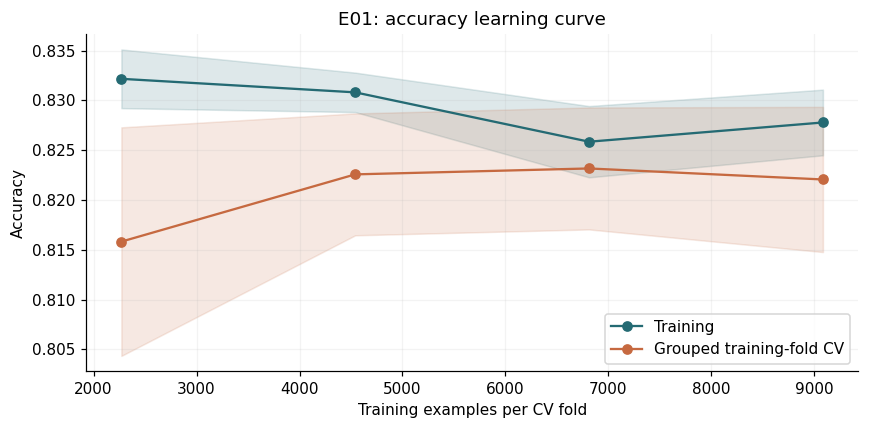

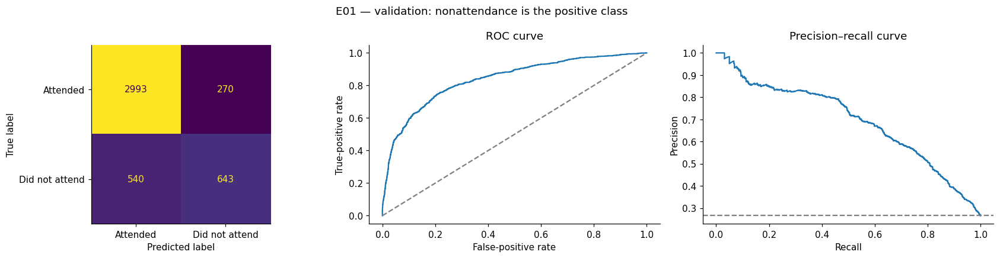

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
E01,0.8178,0.7304,0.7043,0.5435,0.6135,0.8363,0.6932


**E01:** validation accuracy **81.78%**; nonattendance recall **54.35%**. Missed **540 of 1,183** nonattenders at threshold 0.50.

Saved this run: /content/mics_project/20261017T214243-e13712d9/results/runs/E01/20261017T214332-e5256835


In [18]:
def run_E01(C=1.0):
    model = LogisticRegression(C=C,max_iter=2000,random_state=SEED)
    return run_classical_experiment('E01','baseline',model)

result_E01 = run_E01(C=1.0)


### E02 — Tune logistic regularization

The cell below searches `C={0.1, 1, 10}` using grouped training CV and AP scoring, then evaluates the selected pipeline on validation data.


Training E02 LogisticRegression


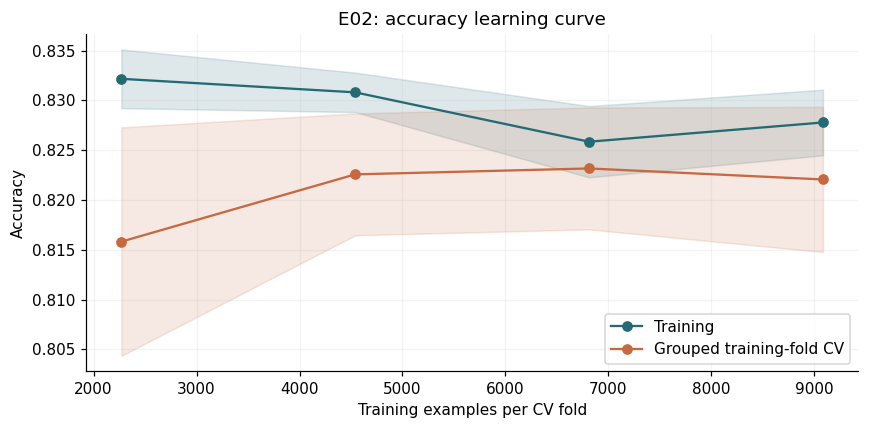

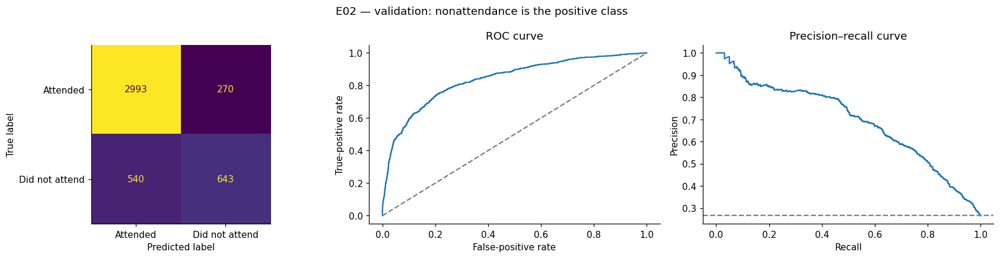

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
E02,0.8178,0.7304,0.7043,0.5435,0.6135,0.8363,0.6932


**E02:** validation accuracy **81.78%**; nonattendance recall **54.35%**. Missed **540 of 1,183** nonattenders at threshold 0.50.

Saved this run: /content/mics_project/20261017T214243-e13712d9/results/runs/E02/20261017T214341-b348a7c9


In [19]:
def run_E02(C_values=(.1,1.,10.)):
    model = LogisticRegression(max_iter=2000,random_state=SEED)
    return run_classical_experiment('E02','baseline',model,{'model__C':list(C_values)})

result_E02 = run_E02(C_values=(.1,1.,10.))


### E03 — Random-forest baseline

The cell below fits 150 trees with baseline features and minimum leaf size 1. Training and validation AP help assess generalization.


Training E03 RandomForestClassifier


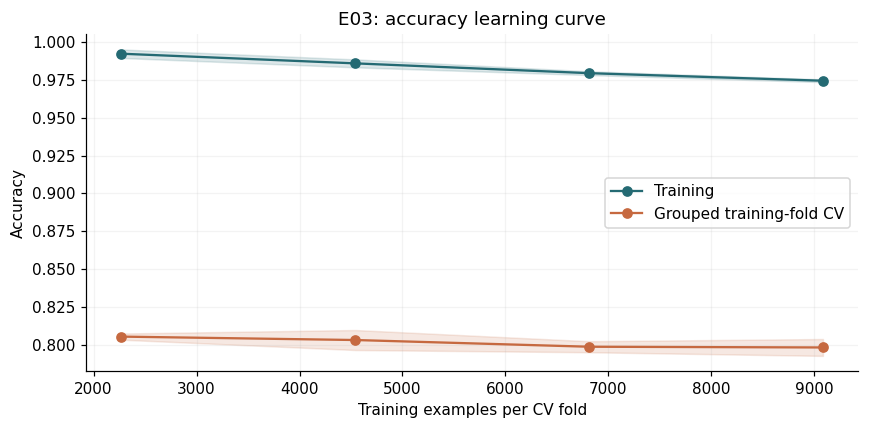

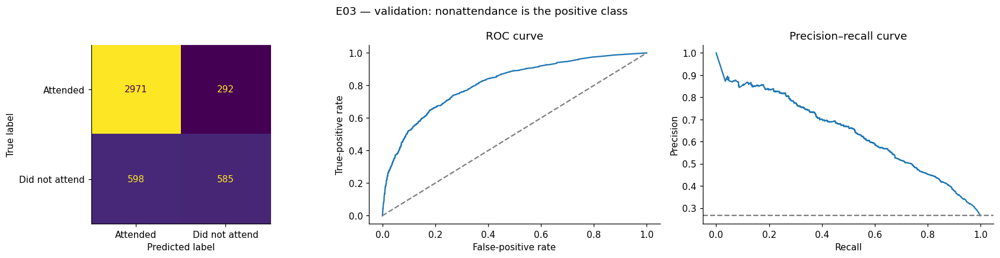

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
E03,0.7998,0.7025,0.667,0.4945,0.568,0.8101,0.6369


**E03:** validation accuracy **79.98%**; nonattendance recall **49.45%**. Missed **598 of 1,183** nonattenders at threshold 0.50.

Saved this run: /content/mics_project/20261017T214243-e13712d9/results/runs/E03/20261017T214353-87659b13


In [20]:
def run_E03(n_estimators=150, min_samples_leaf=1):
    model = RandomForestClassifier(n_estimators=n_estimators,min_samples_leaf=min_samples_leaf,random_state=SEED,n_jobs=N_JOBS)
    return run_classical_experiment('E03','baseline',model)

result_E03 = run_E03(n_estimators=150,min_samples_leaf=1)


### E04 — Tune the enhanced random forest

The cell below searches leaf sizes `{2, 5}` and depths `{12, unrestricted}` with 150 trees and enhanced inputs. This changes both representation and model constraints.


Training E04 RandomForestClassifier


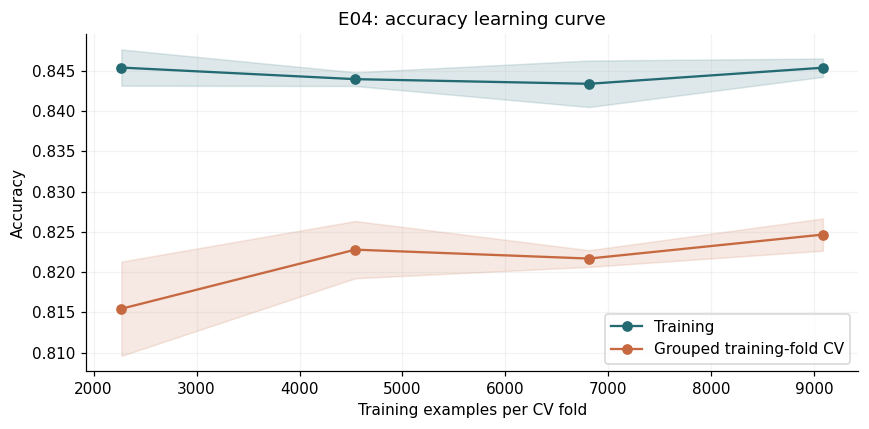

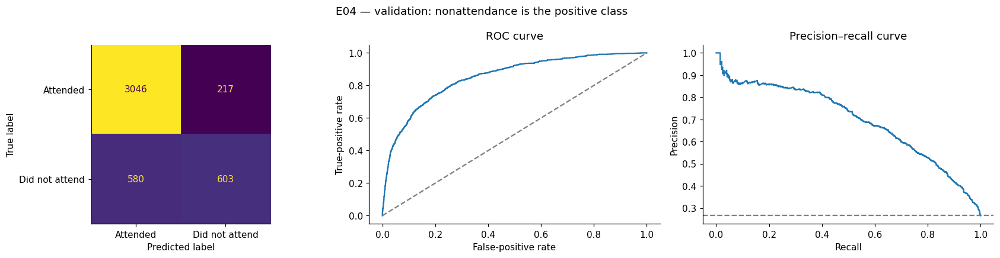

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
E04,0.8207,0.7216,0.7354,0.5097,0.6021,0.8496,0.6971


**E04:** validation accuracy **82.07%**; nonattendance recall **50.97%**. Missed **580 of 1,183** nonattenders at threshold 0.50.

Saved this run: /content/mics_project/20261017T214243-e13712d9/results/runs/E04/20261017T214409-e82e56e9


In [21]:
def run_E04(n_estimators=150, leaf_values=(2,5), depths=(None,12)):
    model = RandomForestClassifier(n_estimators=n_estimators,random_state=SEED,n_jobs=N_JOBS)
    return run_classical_experiment('E04','enhanced',model,{'model__min_samples_leaf':list(leaf_values),'model__max_depth':list(depths)})

result_E04 = run_E04(n_estimators=150,leaf_values=(2,5),depths=(None,12))


## 14. Train neural models with tf.data

Each network uses 64/32 ReLU hidden units, sigmoid output, Adam and binary cross-entropy. `tf.data` batches inputs. Early stopping restores the best validation-loss weights, with patience 5 and a maximum of 40 epochs.


### E05 — Neural baseline

The cell below trains the baseline network with learning rate 0.001, batch size 128 and no dropout or L2 penalty. It displays loss, accuracy and evaluation plots.


Training E05 Keras MLP
Epoch 1/40
106/106 - 2s - 16ms/step - accuracy: 0.7620 - loss: 0.5000 - roc_auc: 0.7513 - val_accuracy: 0.8124 - val_loss: 0.4368 - val_roc_auc: 0.8265
Epoch 2/40
106/106 - 0s - 3ms/step - accuracy: 0.8253 - loss: 0.4128 - roc_auc: 0.8449 - val_accuracy: 0.8203 - val_loss: 0.4141 - val_roc_auc: 0.8446
Epoch 3/40
106/106 - 0s - 3ms/step - accuracy: 0.8312 - loss: 0.3969 - roc_auc: 0.8574 - val_accuracy: 0.8252 - val_loss: 0.4071 - val_roc_auc: 0.8511
Epoch 4/40
106/106 - 0s - 3ms/step - accuracy: 0.8320 - loss: 0.3907 - roc_auc: 0.8621 - val_accuracy: 0.8270 - val_loss: 0.4048 - val_roc_auc: 0.8535
Epoch 5/40
106/106 - 0s - 3ms/step - accuracy: 0.8333 - loss: 0.3864 - roc_auc: 0.8652 - val_accuracy: 0.8273 - val_loss: 0.4010 - val_roc_auc: 0.8557
Epoch 6/40
106/106 - 0s - 3ms/step - accuracy: 0.8334 - loss: 0.3837 - roc_auc: 0.8678 - val_accuracy: 0.8243 - val_loss: 0.4039 - val_roc_auc: 0.8556
Epoch 7/40
106/106 - 0s - 3ms/step - accuracy: 0.8339 - loss: 0.3797 -

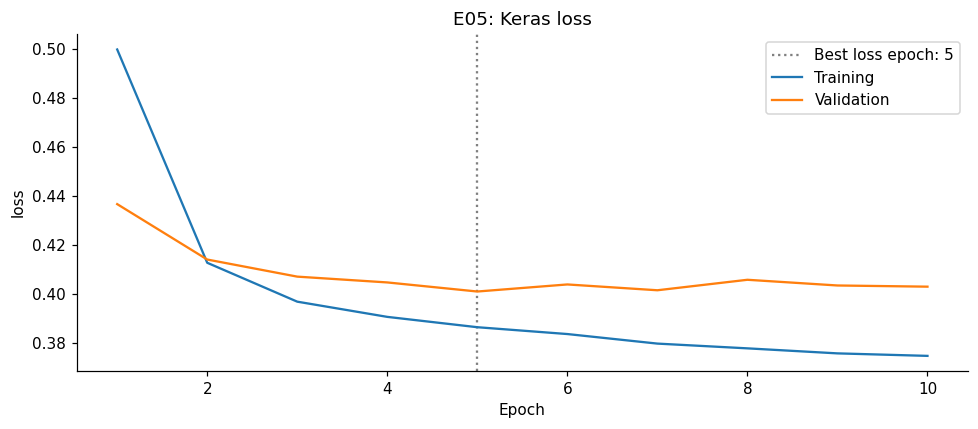

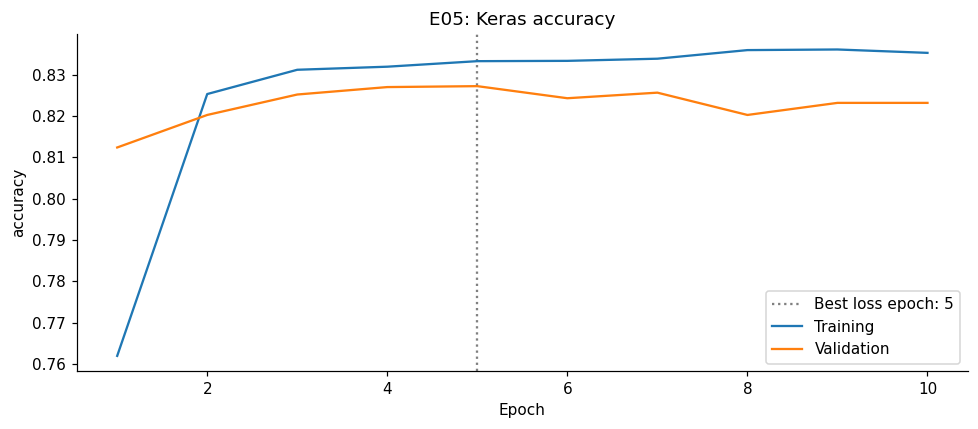

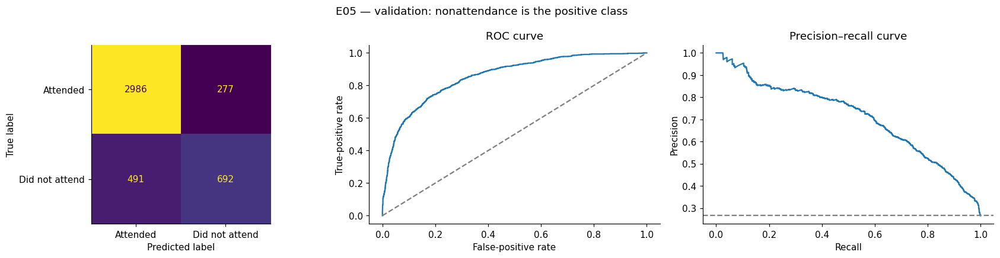

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
E05,0.8273,0.75,0.7141,0.585,0.6431,0.8558,0.7102


**E05:** validation accuracy **82.73%**; nonattendance recall **58.50%**. Missed **491 of 1,183** nonattenders at threshold 0.50.

Saved this run: /content/mics_project/20261017T214243-e13712d9/results/runs/E05/20261017T214437-d1820830


In [22]:
def run_E05(epochs=40, batch_size=128, learning_rate=.001):
    return run_neural_experiment('E05','baseline',dropout=0.,learning_rate=learning_rate,l2=0.,epochs=epochs,batch_size=batch_size)

result_E05 = run_E05(epochs=40,batch_size=128,learning_rate=.001)


### E06 — Neural network with enhanced inputs

The cell below keeps E05’s architecture and settings but uses age bands and log-transformed household count. It trains a new model independently of E05.


Training E06 Keras MLP
Epoch 1/40
106/106 - 2s - 15ms/step - accuracy: 0.7648 - loss: 0.4959 - roc_auc: 0.7546 - val_accuracy: 0.8126 - val_loss: 0.4334 - val_roc_auc: 0.8299
Epoch 2/40
106/106 - 0s - 3ms/step - accuracy: 0.8242 - loss: 0.4104 - roc_auc: 0.8471 - val_accuracy: 0.8261 - val_loss: 0.4111 - val_roc_auc: 0.8466
Epoch 3/40
106/106 - 0s - 3ms/step - accuracy: 0.8297 - loss: 0.3967 - roc_auc: 0.8576 - val_accuracy: 0.8273 - val_loss: 0.4065 - val_roc_auc: 0.8507
Epoch 4/40
106/106 - 0s - 3ms/step - accuracy: 0.8313 - loss: 0.3918 - roc_auc: 0.8613 - val_accuracy: 0.8284 - val_loss: 0.4043 - val_roc_auc: 0.8530
Epoch 5/40
106/106 - 0s - 3ms/step - accuracy: 0.8318 - loss: 0.3879 - roc_auc: 0.8638 - val_accuracy: 0.8282 - val_loss: 0.4000 - val_roc_auc: 0.8553
Epoch 6/40
106/106 - 0s - 4ms/step - accuracy: 0.8323 - loss: 0.3852 - roc_auc: 0.8661 - val_accuracy: 0.8266 - val_loss: 0.4027 - val_roc_auc: 0.8553
Epoch 7/40
106/106 - 1s - 6ms/step - accuracy: 0.8341 - loss: 0.3813 -

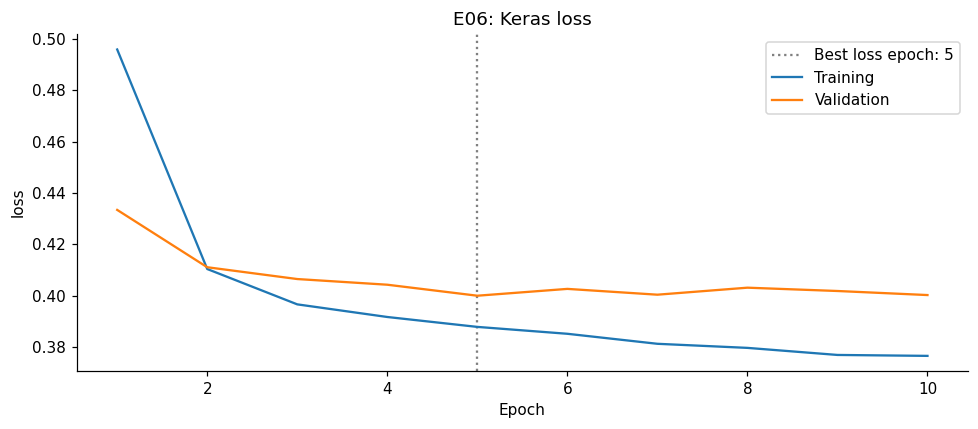

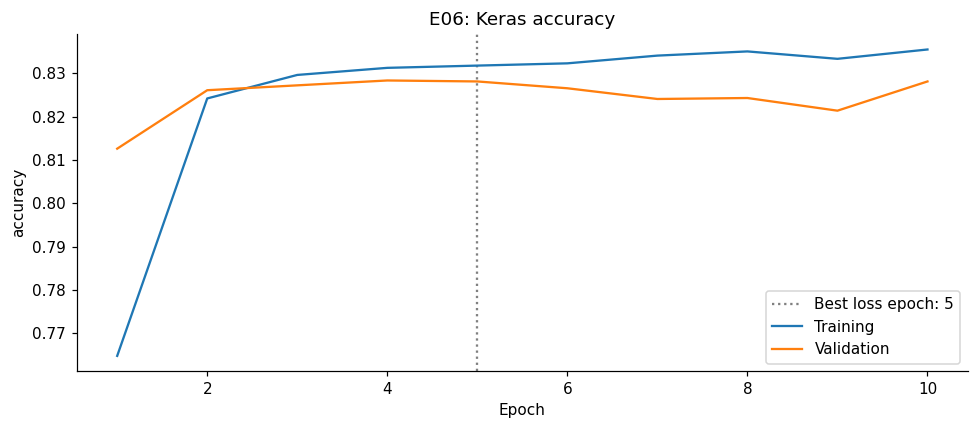

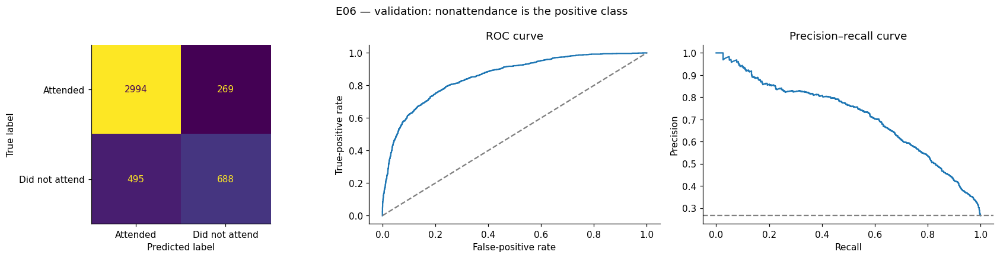

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
E06,0.8282,0.7496,0.7189,0.5816,0.643,0.8553,0.7127


**E06:** validation accuracy **82.82%**; nonattendance recall **58.16%**. Missed **495 of 1,183** nonattenders at threshold 0.50.

Saved this run: /content/mics_project/20261017T214243-e13712d9/results/runs/E06/20261017T214445-0da97061


In [23]:
def run_E06(epochs=40, batch_size=128, learning_rate=.001):
    return run_neural_experiment('E06','enhanced',dropout=0.,learning_rate=learning_rate,l2=0.,epochs=epochs,batch_size=batch_size)

result_E06 = run_E06(epochs=40,batch_size=128,learning_rate=.001)


### E07 — Regularized neural network

The cell below uses enhanced inputs, dropout 0.25, L2 0.0001 and learning rate 0.0003. These combined changes test a more constrained training configuration.


Training E07 Keras MLP
Epoch 1/40
106/106 - 2s - 15ms/step - accuracy: 0.7028 - loss: 0.6090 - roc_auc: 0.5764 - val_accuracy: 0.7346 - val_loss: 0.5429 - val_roc_auc: 0.7263
Epoch 2/40
106/106 - 0s - 3ms/step - accuracy: 0.7460 - loss: 0.5184 - roc_auc: 0.7527 - val_accuracy: 0.7670 - val_loss: 0.4811 - val_roc_auc: 0.8101
Epoch 3/40
106/106 - 0s - 3ms/step - accuracy: 0.7795 - loss: 0.4737 - roc_auc: 0.8038 - val_accuracy: 0.8115 - val_loss: 0.4499 - val_roc_auc: 0.8277
Epoch 4/40
106/106 - 0s - 3ms/step - accuracy: 0.8071 - loss: 0.4516 - roc_auc: 0.8205 - val_accuracy: 0.8178 - val_loss: 0.4377 - val_roc_auc: 0.8349
Epoch 5/40
106/106 - 0s - 3ms/step - accuracy: 0.8110 - loss: 0.4434 - roc_auc: 0.8265 - val_accuracy: 0.8194 - val_loss: 0.4315 - val_roc_auc: 0.8394
Epoch 6/40
106/106 - 0s - 3ms/step - accuracy: 0.8159 - loss: 0.4348 - roc_auc: 0.8347 - val_accuracy: 0.8237 - val_loss: 0.4272 - val_roc_auc: 0.8434
Epoch 7/40
106/106 - 0s - 3ms/step - accuracy: 0.8143 - loss: 0.4336 -

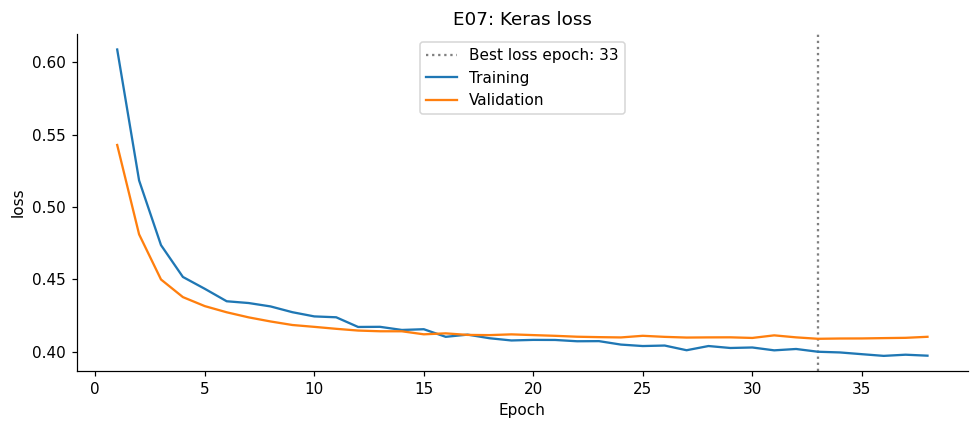

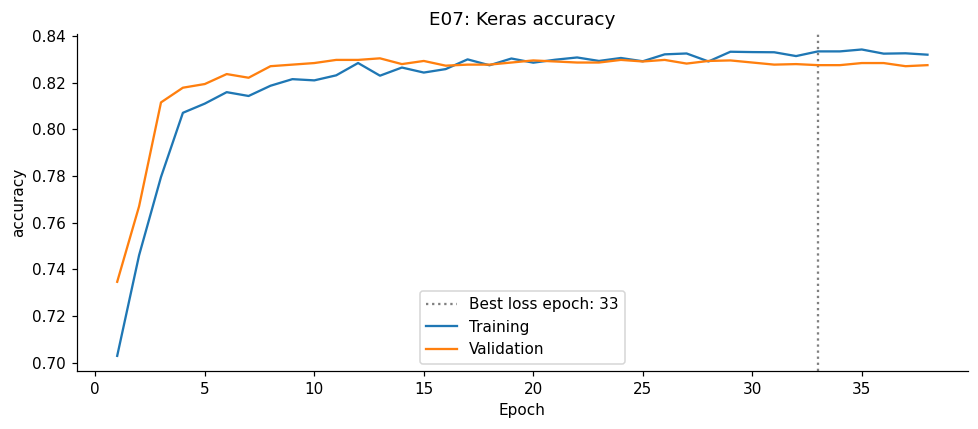

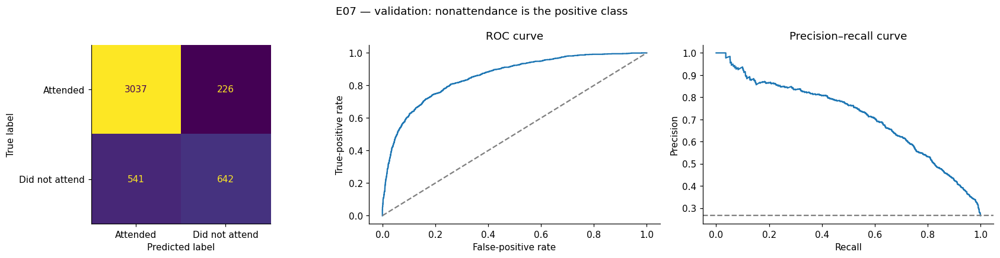

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
E07,0.8275,0.7367,0.7396,0.5427,0.626,0.8554,0.7124


**E07:** validation accuracy **82.75%**; nonattendance recall **54.27%**. Missed **541 of 1,183** nonattenders at threshold 0.50.

Saved this run: /content/mics_project/20261017T214243-e13712d9/results/runs/E07/20261017T214453-cd258795


In [24]:
def run_E07(epochs=40, batch_size=128, learning_rate=.0003, dropout=.25, l2=.0001):
    return run_neural_experiment('E07','enhanced',dropout=dropout,learning_rate=learning_rate,l2=l2,epochs=epochs,batch_size=batch_size)

result_E07 = run_E07(epochs=40,batch_size=128,learning_rate=.0003,dropout=.25,l2=.0001)


## 15. Add three accuracy-oriented searches

The following cells tune accuracy using grouped training CV and evaluate validation predictions at threshold 0.5. The test partition is excluded from tuning.


### E08 — Accuracy-tuned random forest

The cell below searches a 200-tree enhanced forest: depth `{10, 20, unrestricted}`, leaf size `{2, 8}` and feature sampling `{'sqrt', 0.8}`.


Training E08 RandomForestClassifier


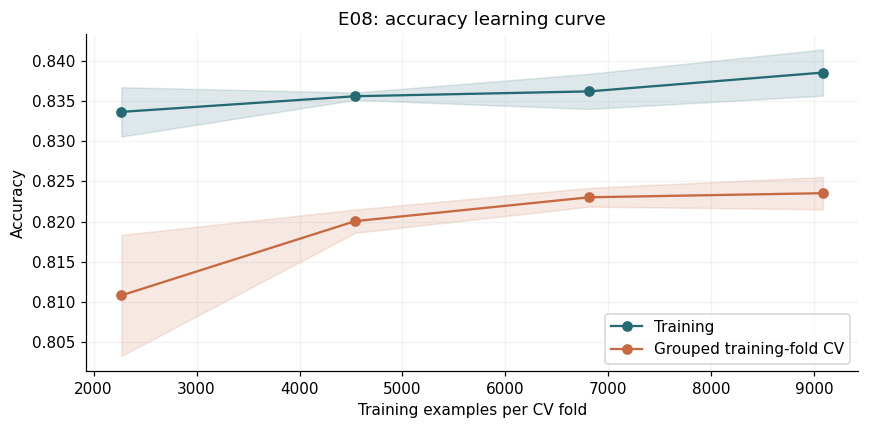

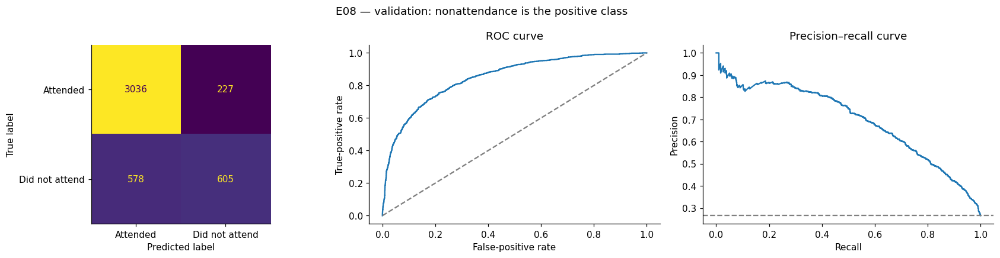

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
E08,0.8189,0.7209,0.7272,0.5114,0.6005,0.8496,0.6973


**E08:** validation accuracy **81.89%**; nonattendance recall **51.14%**. Missed **578 of 1,183** nonattenders at threshold 0.50.

Saved this run: /content/mics_project/20261017T214243-e13712d9/results/runs/E08/20261017T214510-db3c6ae7


In [25]:
def run_E08():
    model = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=N_JOBS)
    return run_classical_experiment('E08','enhanced',model,
        {'model__max_depth':[10,20,None], 'model__min_samples_leaf':[2,8],
         'model__max_features':['sqrt',0.8]}, scoring='accuracy')

result_E08 = run_E08()


### E09 — Baseline gradient boosting

The cell below searches 200-iteration histogram boosting with baseline inputs: learning rate `{0.05, 0.1}`, leaves `{15, 31}` and L2 `{1, 10}`. Internal early stopping is disabled for grouped CV.


Training E09 HistGradientBoostingClassifier


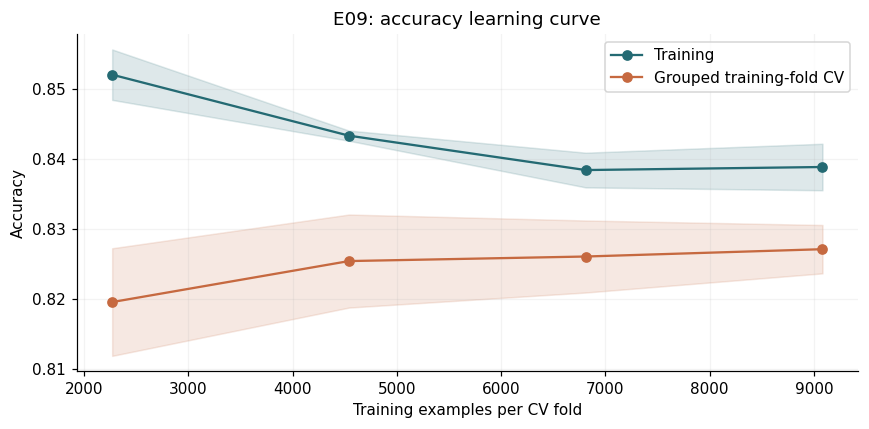

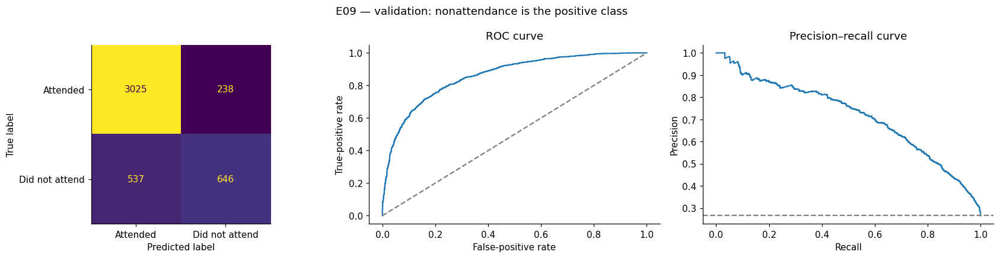

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
E09,0.8257,0.7366,0.7308,0.5461,0.6251,0.8593,0.7162


**E09:** validation accuracy **82.57%**; nonattendance recall **54.61%**. Missed **537 of 1,183** nonattenders at threshold 0.50.

Saved this run: /content/mics_project/20261017T214243-e13712d9/results/runs/E09/20261017T214706-3fa19769


In [26]:
from sklearn.ensemble import HistGradientBoostingClassifier

def run_E09():
    model = HistGradientBoostingClassifier(max_iter=200, early_stopping=False, random_state=SEED)
    return run_classical_experiment('E09','baseline',model,
        {'model__learning_rate':[0.05,0.1], 'model__max_leaf_nodes':[15,31],
         'model__l2_regularization':[1.0,10.0]}, scoring='accuracy')

result_E09 = run_E09()


### E10 — Enhanced gradient boosting

The cell below repeats E09’s search using enhanced features. Comparing the two runs assesses whether the added representation helps boosting.


Training E10 HistGradientBoostingClassifier


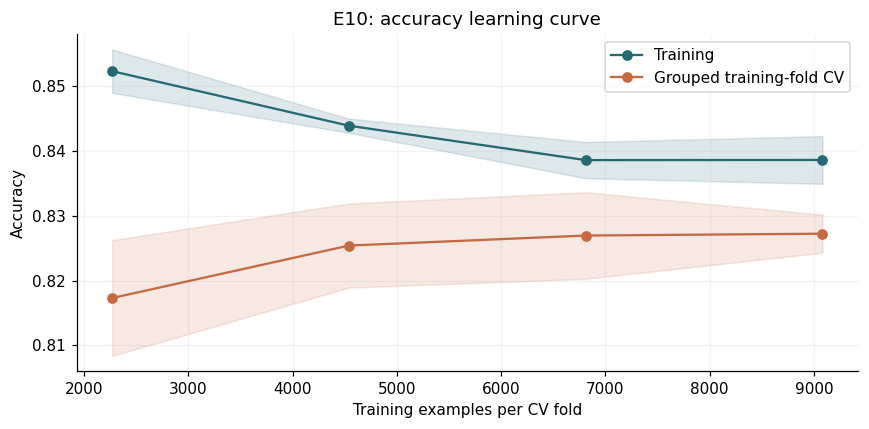

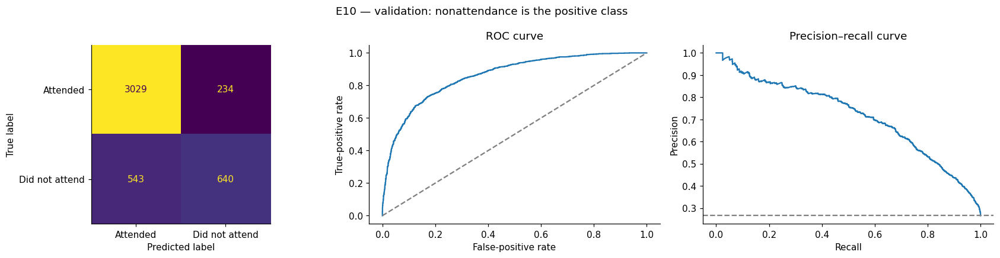

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
E10,0.8252,0.7346,0.7323,0.541,0.6223,0.8594,0.7163


**E10:** validation accuracy **82.52%**; nonattendance recall **54.10%**. Missed **543 of 1,183** nonattenders at threshold 0.50.

Saved this run: /content/mics_project/20261017T214243-e13712d9/results/runs/E10/20261017T214802-9a6aa1bd


In [27]:
from sklearn.ensemble import HistGradientBoostingClassifier

def run_E10():
    model = HistGradientBoostingClassifier(max_iter=200, early_stopping=False, random_state=SEED)
    return run_classical_experiment('E10','enhanced',model,
        {'model__learning_rate':[0.05,0.1], 'model__max_leaf_nodes':[15,31],
         'model__l2_regularization':[1.0,10.0]}, scoring='accuracy')

result_E10 = run_E10()


### View all experiment figures together

The cell below repeats the latest completed E01–E10 figures in one place. Every figure also appears beneath its own experiment. No download or retraining is needed.


### E01
Recorded run: `20261017T214332-e5256835`

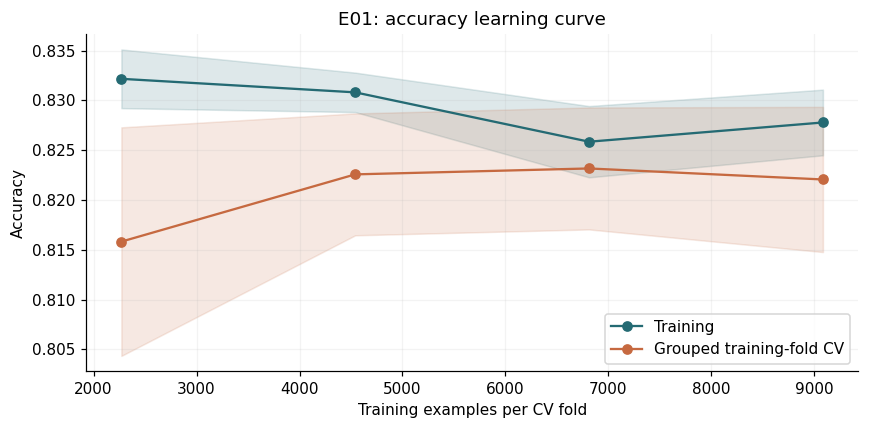

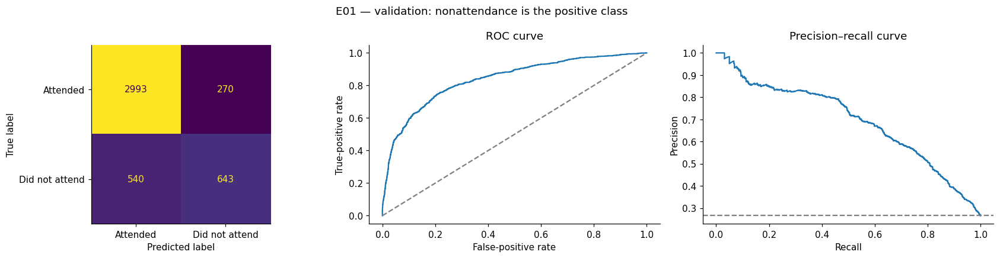

### E02
Recorded run: `20261017T214341-b348a7c9`

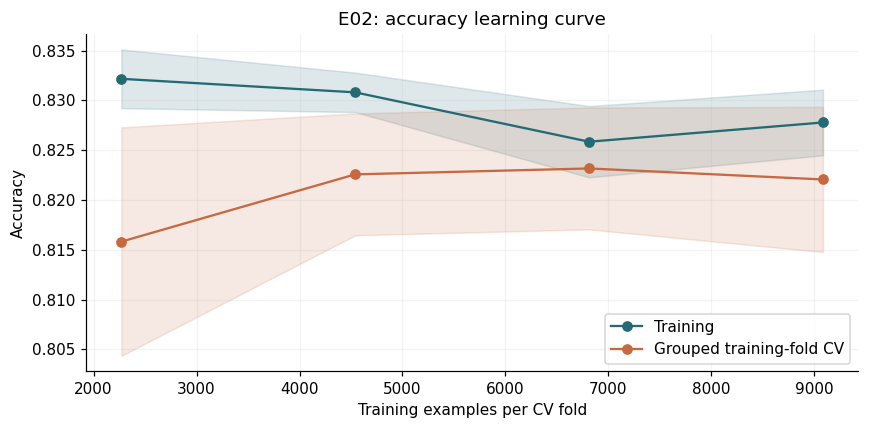

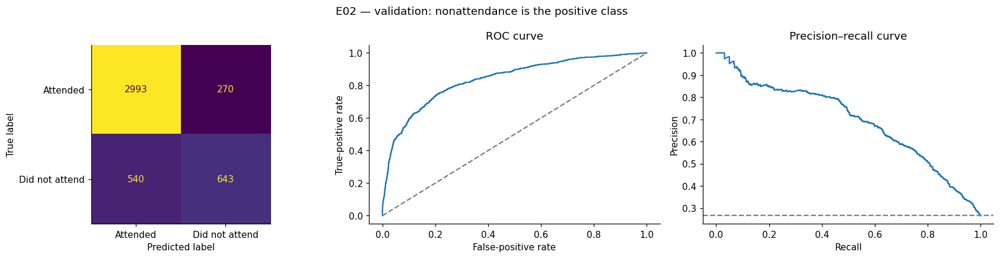

### E03
Recorded run: `20261017T214353-87659b13`

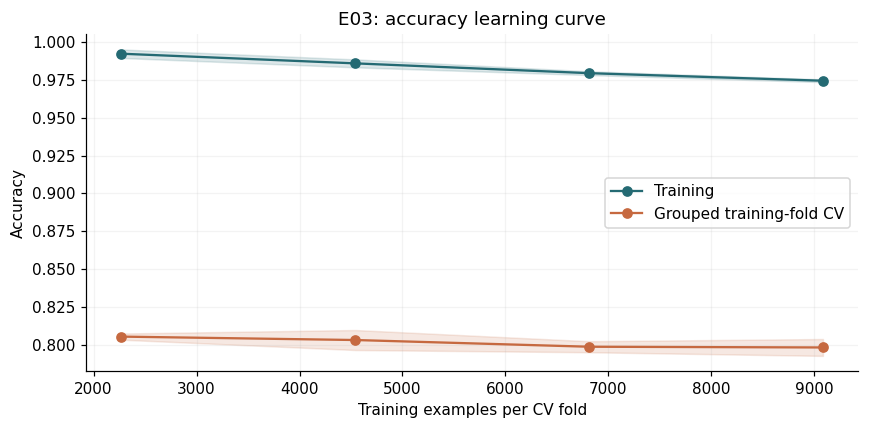

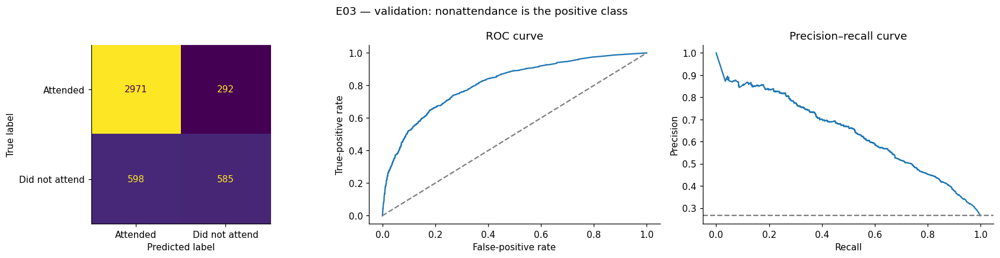

### E04
Recorded run: `20261017T214409-e82e56e9`

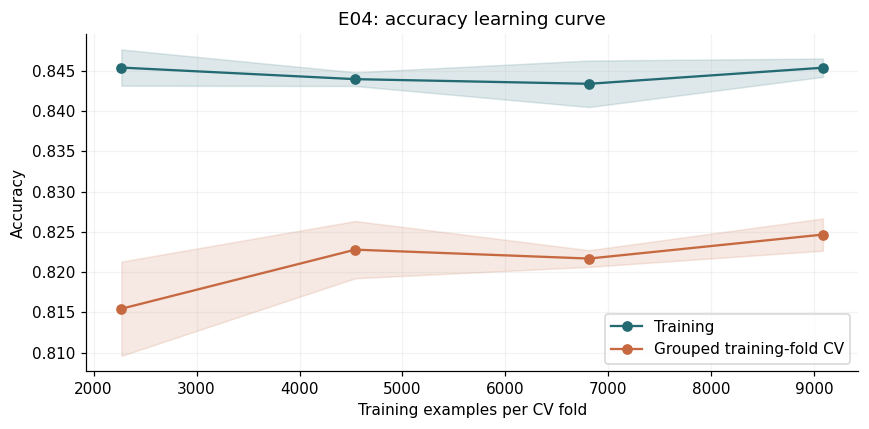

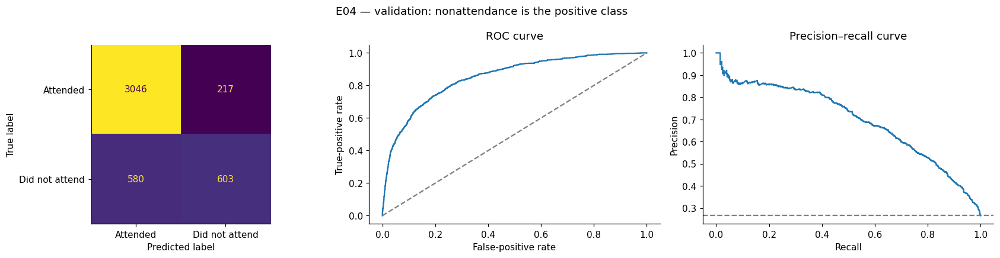

### E05
Recorded run: `20261017T214437-d1820830`

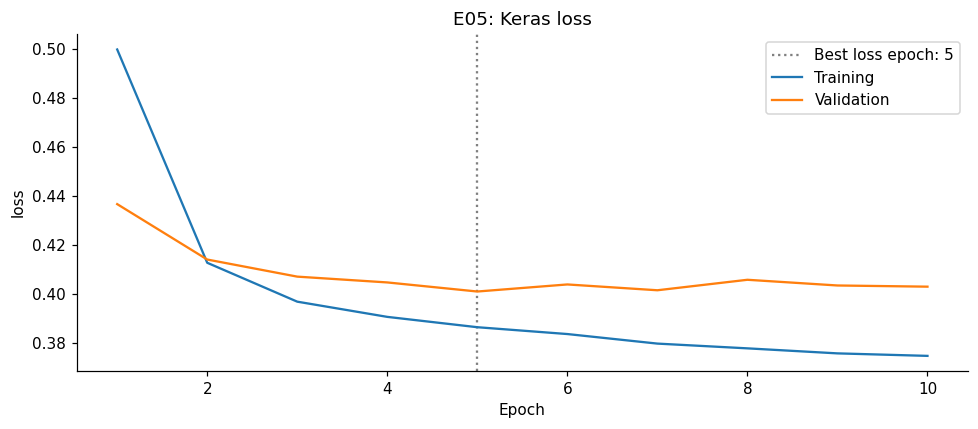

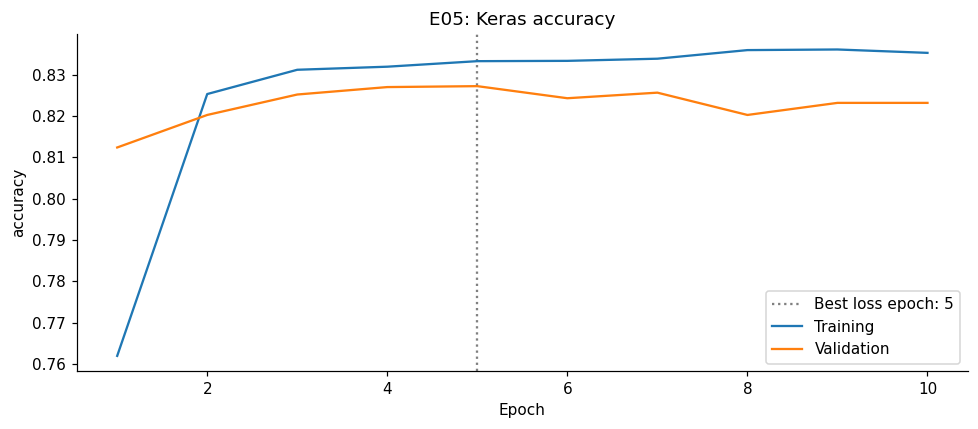

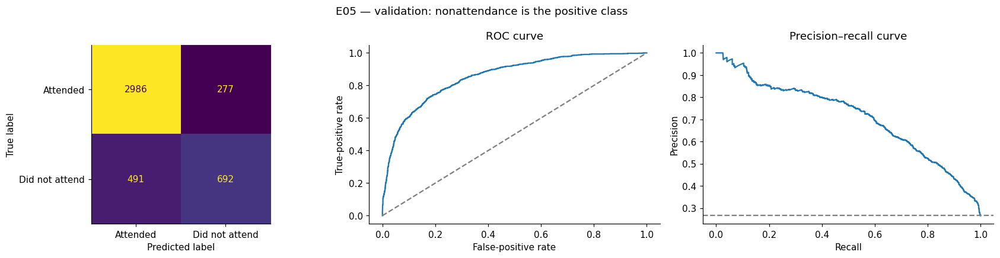

### E06
Recorded run: `20261017T214445-0da97061`

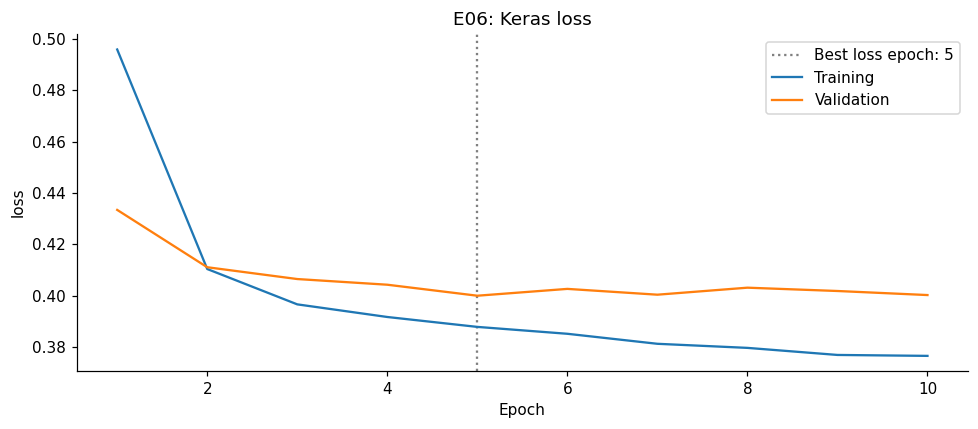

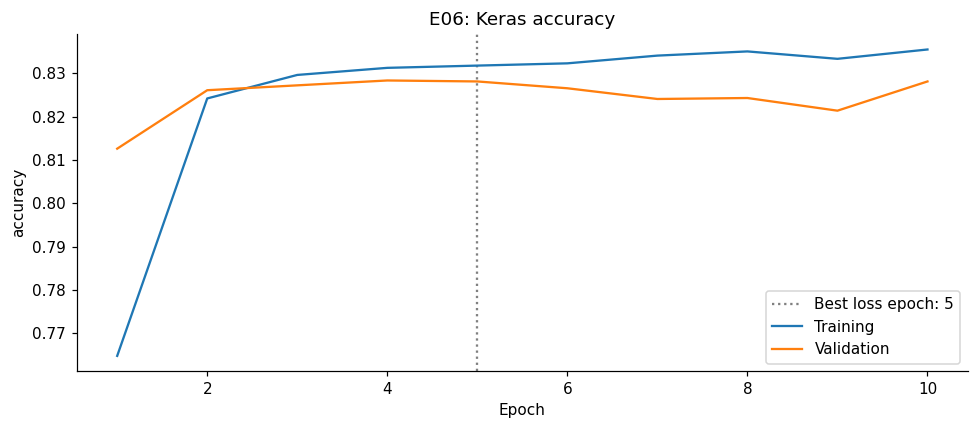

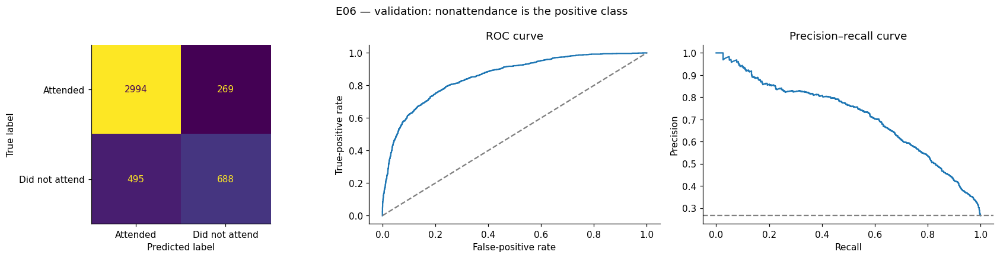

### E07
Recorded run: `20261017T214453-cd258795`

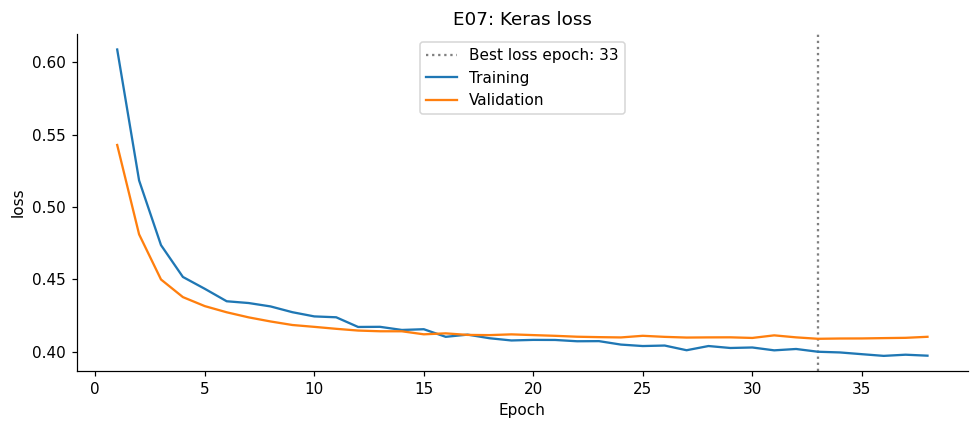

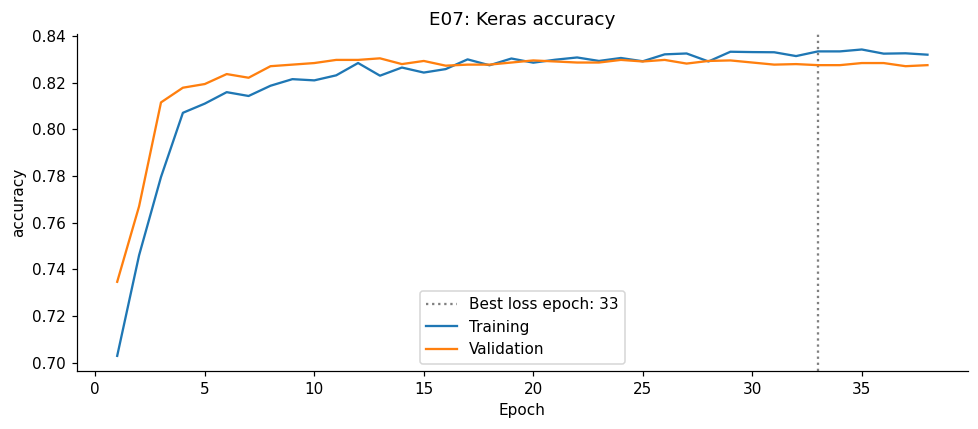

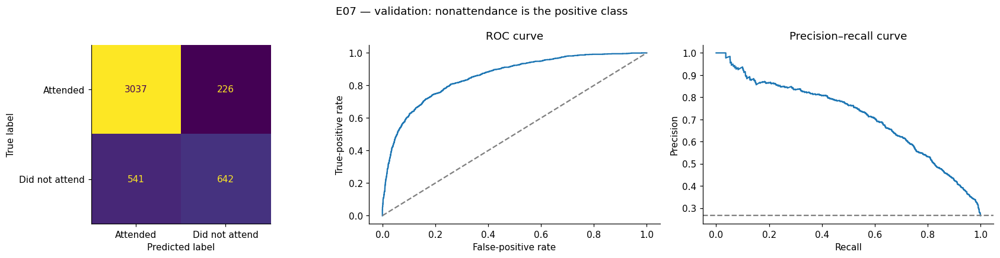

### E08
Recorded run: `20261017T214510-db3c6ae7`

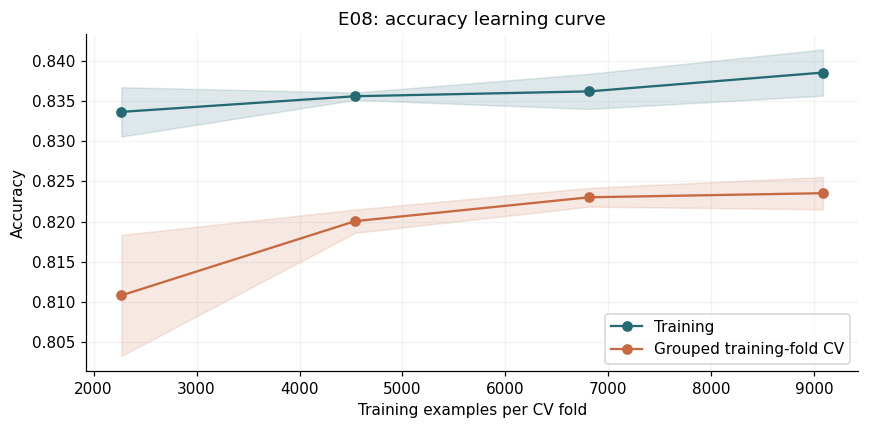

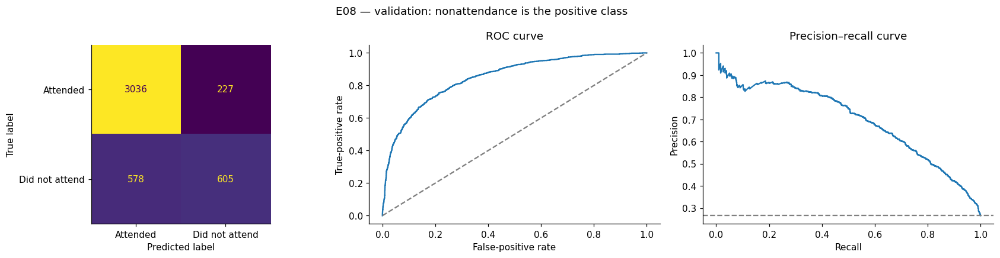

### E09
Recorded run: `20261017T214706-3fa19769`

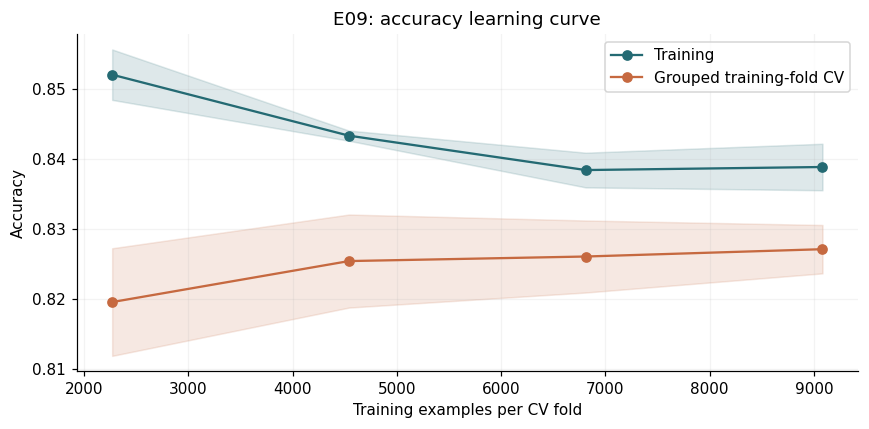

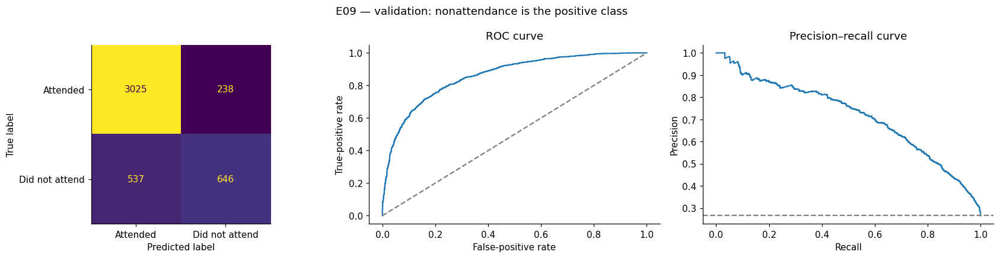

### E10
Recorded run: `20261017T214802-9a6aa1bd`

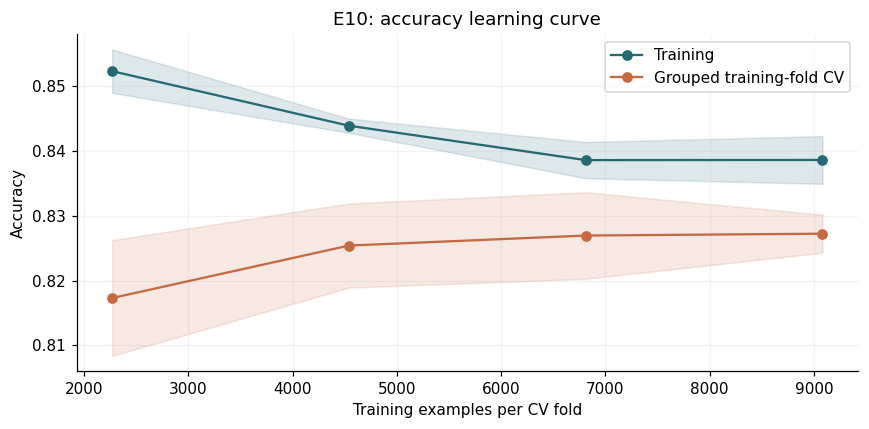

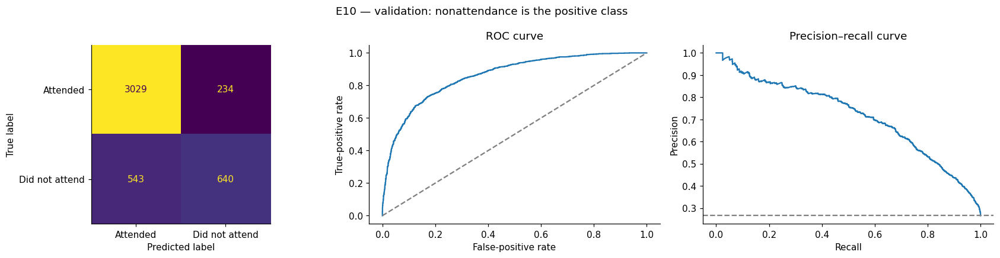

In [28]:
from IPython.display import Image, Markdown
registry = pd.read_csv(RESULTS/'experiments.csv',dtype={'experiment':str,'tensorboard_run_id':str})
for experiment in [f'E{i:02d}' for i in range(1,11)]:
    rows = registry.loc[registry['experiment'].eq(experiment)]
    if len(rows)!=1:
        print(f'{experiment}: no unique completed record; skipping.')
        continue
    run_id = rows.iloc[0]['tensorboard_run_id']
    folder = RESULTS/'runs'/experiment/run_id
    display(Markdown(f'### {experiment}\nRecorded run: `{run_id}`'))
    for name in ['accuracy_learning_curve.png','loss_curve.png','accuracy_curve.png','validation_evaluation.png']:
        image_path = folder/name
        if image_path.is_file(): display(Image(filename=str(image_path)))


## 16. Compare all ten runs

The cell below compares validation metrics at threshold 0.50, overlays ROC/PR curves, and compares neural epoch curves and classical accuracy learning curves separately. The majority baseline and the exploratory 87% target provide context; neither replaces recall or AP.


,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
experiment,,,,,,,
E06,0.8282,0.7496,0.7189,0.5816,0.6430,0.8553,0.7127
E07,0.8275,0.7367,0.7396,0.5427,0.6260,0.8554,0.7124
E05,0.8273,0.7500,0.7141,0.5850,0.6431,0.8558,0.7102
E09,0.8257,0.7366,0.7308,0.5461,0.6251,0.8593,0.7162
E10,0.8252,0.7346,0.7323,0.5410,0.6223,0.8594,0.7163
E04,0.8207,0.7216,0.7354,0.5097,0.6021,0.8496,0.6971
E08,0.8189,0.7209,0.7272,0.5114,0.6005,0.8496,0.6973
E01,0.8178,0.7304,0.7043,0.5435,0.6135,0.8363,0.6932
E02,0.8178,0.7304,0.7043,0.5435,0.6135,0.8363,0.6932


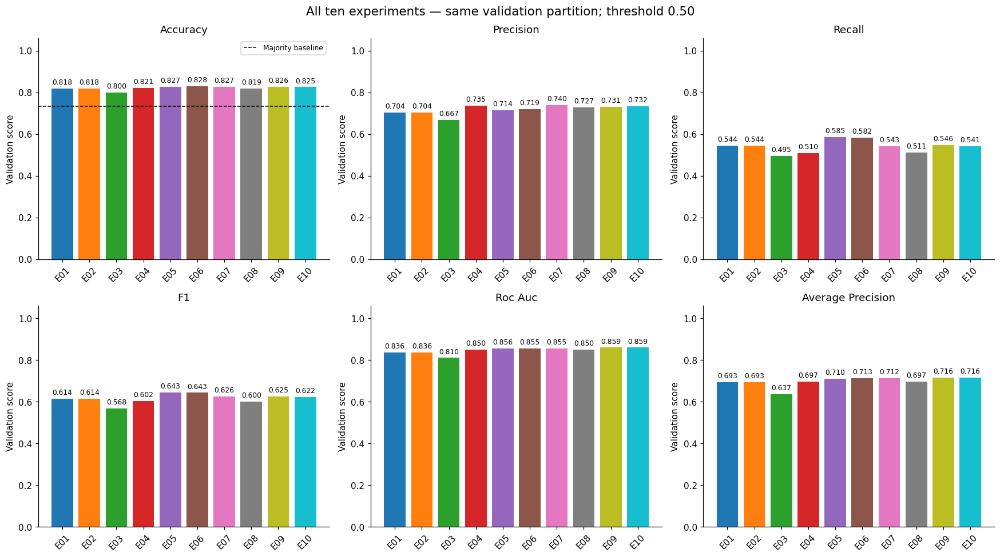

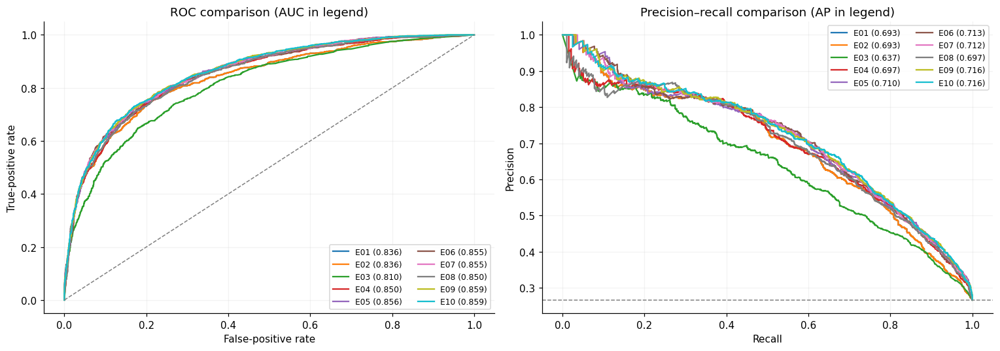

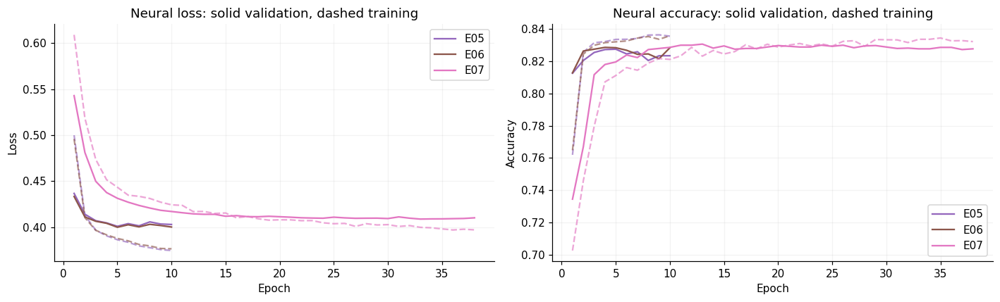

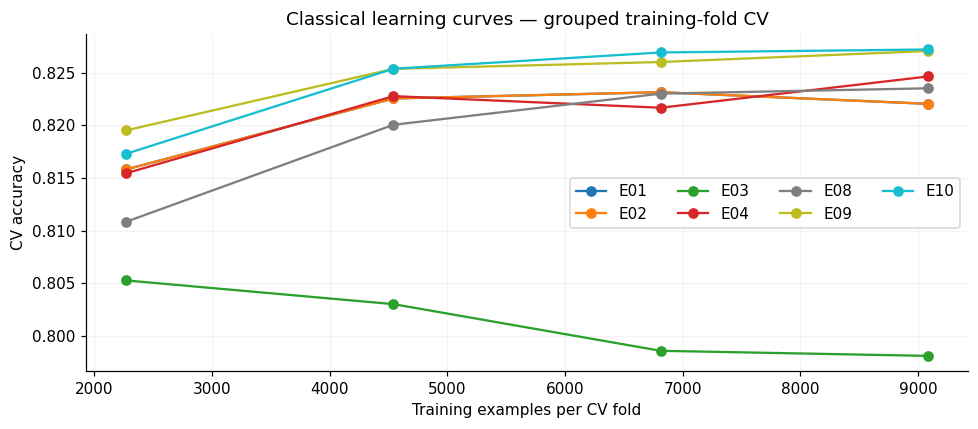

**Accuracy leader:** E06 (82.82%); majority baseline 73.39%. The exploratory 87% target is not met. These are validation results. Model selection below uses AP to reflect the minority outcome.

In [29]:
required = {f'E{i:02d}' for i in range(1,11)}
assert required == {r['experiment'] for r in experiment_rows}, 'Complete E01–E10 first.'
assert len(experiment_rows)==10, 'Each experiment must have one current result.'
accuracy_comparison = pd.DataFrame(experiment_rows).sort_values(
    ['validation_accuracy','experiment'],ascending=[False,True])
metric_columns = ['accuracy','balanced_accuracy','precision','recall','f1','roc_auc','average_precision']
display(accuracy_comparison.set_index('experiment')[[f'validation_{m}' for m in metric_columns]]
        .rename(columns=lambda name:name.replace('validation_','')).round(4))
majority_class = int(pd.Series(y_train).mode().iloc[0])
majority_accuracy = accuracy_score(parts['validation'][1],
    np.full(len(parts['validation'][1]),majority_class))
accuracy_winner = accuracy_comparison.iloc[0]
accuracy_choice = {'experiment':accuracy_winner['experiment'], 'threshold':0.5,
    'selection_metric':'validation_accuracy', 'validation_accuracy':float(accuracy_winner['validation_accuracy']),
    'majority_validation_accuracy':float(majority_accuracy), 'target_accuracy':0.87,
    'target_met_on_validation':bool(accuracy_winner['validation_accuracy']>=.87),
    'test_evaluated_for_accuracy_extension':False, 'test_previously_inspected':True}
accuracy_comparison.to_csv(RESULTS/'accuracy_comparison.csv',index=False)
(RESULTS/'accuracy_selection.json').write_text(json.dumps(accuracy_choice,indent=2),encoding='utf-8')
ordered = accuracy_comparison.sort_values('experiment').set_index('experiment')
colors = {exp:plt.get_cmap('tab10')(i) for i,exp in enumerate(ordered.index)}
with start_tracked_run('all-experiments-comparison','validation-comparison',accuracy_choice) as run:
    run.log({'comparison/metrics':accuracy_comparison,
             'comparison/majority_accuracy':majority_accuracy})
    fig,axes = plt.subplots(2,3,figsize=(16,9))
    for ax,metric in zip(axes.flat,['accuracy','precision','recall','f1','roc_auc','average_precision']):
        values = ordered[f'validation_{metric}']
        bars = ax.bar(values.index,values,color=[colors[e] for e in values.index])
        ax.bar_label(bars,labels=[f'{v:.3f}' for v in values],fontsize=8,padding=3)
        ax.set(ylim=(0,1.06),title=metric.replace('_',' ').title(),ylabel='Validation score')
        ax.tick_params(axis='x',rotation=45)
        if metric=='accuracy':
            ax.axhline(majority_accuracy,color='black',ls='--',lw=1,label='Majority baseline')
            ax.legend(fontsize=8)
    fig.suptitle('All ten experiments — same validation partition; threshold 0.50',fontsize=14)
    fig.tight_layout(); fig.savefig(RESULTS/'all_run_metrics.png',bbox_inches='tight')
    run.log({'comparison/all_run_metrics':fig}); plt.show(); plt.close(fig)

    fig,axes = plt.subplots(1,2,figsize=(14,5))
    truth = parts['validation'][1].to_numpy()
    for exp in ordered.index:
        prob = validation_probabilities[exp]
        fpr,tpr,_ = roc_curve(truth,prob)
        precision,recall,_ = precision_recall_curve(truth,prob)
        axes[0].plot(fpr,tpr,color=colors[exp],label=f'{exp} ({ordered.loc[exp,"validation_roc_auc"]:.3f})')
        axes[1].plot(recall,precision,color=colors[exp],label=f'{exp} ({ordered.loc[exp,"validation_average_precision"]:.3f})')
    axes[0].plot([0,1],[0,1],'--',color='gray',lw=1)
    axes[1].axhline(truth.mean(),ls='--',color='gray',lw=1)
    axes[0].set(xlabel='False-positive rate',ylabel='True-positive rate',title='ROC comparison (AUC in legend)')
    axes[1].set(xlabel='Recall',ylabel='Precision',title='Precision–recall comparison (AP in legend)')
    for ax in axes:
        ax.legend(fontsize=8,ncol=2); ax.grid(alpha=.15)
    fig.tight_layout(); fig.savefig(RESULTS/'all_run_roc_pr.png',bbox_inches='tight')
    run.log({'comparison/all_run_roc_pr':fig}); plt.show(); plt.close(fig)

    fig,axes = plt.subplots(1,2,figsize=(13,4))
    for exp,row in ordered.loc[ordered.family.eq('neural')].iterrows():
        history = pd.read_csv(RESULTS/'runs'/exp/row.tensorboard_run_id/'history.csv')
        epochs = np.arange(1,len(history)+1)
        for ax,metric in zip(axes,['loss','accuracy']):
            ax.plot(epochs,history[metric],ls='--',alpha=.65,color=colors[exp])
            ax.plot(epochs,history[f'val_{metric}'],color=colors[exp],label=exp)
            ax.set(xlabel='Epoch',ylabel=metric.title(),title=f'Neural {metric}: solid validation, dashed training')
            ax.grid(alpha=.15)
    for ax in axes: ax.legend()
    fig.tight_layout(); fig.savefig(RESULTS/'neural_curve_comparison.png',bbox_inches='tight')
    run.log({'comparison/neural_epoch_curves':fig}); plt.show(); plt.close(fig)

    fig,ax = plt.subplots(figsize=(9,4))
    for exp,row in ordered.loc[ordered.family.eq('classical')].iterrows():
        curve = pd.read_csv(RESULTS/'runs'/exp/row.tensorboard_run_id/'accuracy_learning_curve.csv')
        ax.plot(curve.train_size,curve.cv_mean,marker='o',color=colors[exp],label=exp)
    ax.set(xlabel='Training examples per CV fold',ylabel='CV accuracy',
           title='Classical learning curves — grouped training-fold CV')
    ax.legend(ncol=4); ax.grid(alpha=.15); fig.tight_layout()
    fig.savefig(RESULTS/'classical_curve_comparison.png',bbox_inches='tight')
    run.log({'comparison/classical_learning_curves':fig}); plt.show(); plt.close(fig)

display(Markdown(f'**Accuracy leader:** {accuracy_choice["experiment"]} '
                 f'({accuracy_choice["validation_accuracy"]:.2%}); majority baseline '
                 f'{majority_accuracy:.2%}. The exploratory 87% target is '
                 f'{"met" if accuracy_choice["target_met_on_validation"] else "not met"}. '
                 'These are validation results. Model selection below uses AP to reflect the minority outcome.'))


## 17. Select and save the final models

The cell below chooses the highest-validation-AP classical and neural models across all ten experiments, then selects each threshold using validation F1. It saves both models and verifies reloaded predictions on validation samples. The test partition is not used.


,experiment,variant,threshold,tensorboard_run_id,validation_average_precision
classical,E10,enhanced,0.35,20261017T214802-9a6aa1bd,0.716331
neural,E06,enhanced,0.38,20261017T214445-0da97061,0.712745


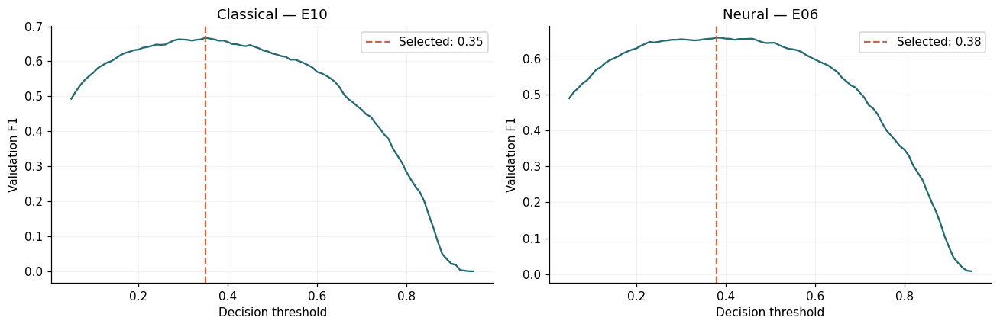

**Selection rule:** highest validation AP within each model family, considering all ten experiments. F1-tuned thresholds use the same validation partition; their scores are selection results, not independent test estimates.

Selected classical and neural models saved; reloaded validation predictions verified.


In [30]:
experiment_table = pd.DataFrame(experiment_rows).sort_values('experiment')
assert len(experiment_table)==10 and experiment_table['experiment'].nunique()==10
selected = {}
for family in ['classical','neural']:
    candidates = experiment_table.loc[experiment_table.family.eq(family)]
    winner = candidates.sort_values(['validation_average_precision','experiment'],ascending=[False,True]).iloc[0]
    exp = winner['experiment']
    p = validation_probabilities[exp]
    threshold_table = pd.DataFrame([
        {'threshold':float(t),'f1':f1_score(parts['validation'][1],p>=t,zero_division=0),
         'distance_to_half':abs(float(t)-.5)} for t in np.linspace(.05,.95,91)])
    threshold = float(threshold_table.sort_values(['f1','distance_to_half','threshold'],
                        ascending=[False,True,True]).iloc[0]['threshold'])
    threshold_table.to_csv(RESULTS/f'{family}_threshold_search.csv',index=False)
    selected[family] = {'experiment':exp,'variant':winner['features'],'threshold':threshold,
                       'tensorboard_run_id':winner['tensorboard_run_id'],
                       'validation_average_precision':float(winner['validation_average_precision'])}
display(pd.DataFrame(selected).T)
(RESULTS/'locked_selection.json').write_text(json.dumps(selected,indent=2),encoding='utf-8')
with start_tracked_run('selected-models','selection',
                      {'selection_metric':'validation_average_precision',
                       'candidate_experiments':experiment_table.experiment.tolist(),
                       'threshold_metric':'validation F1','test_used':False}) as run:
    run.log({'selection/models':pd.DataFrame(selected).T.reset_index(names='family')})
    fig,axes = plt.subplots(1,2,figsize=(12,4))
    for ax,(family,choice) in zip(axes,selected.items()):
        search = pd.read_csv(RESULTS/f'{family}_threshold_search.csv')
        ax.plot(search.threshold,search.f1,color='#246a73')
        ax.axvline(choice['threshold'],ls='--',color='#c66940',label=f'Selected: {choice["threshold"]:.2f}')
        ax.set(xlabel='Decision threshold',ylabel='Validation F1',title=f'{family.title()} — {choice["experiment"]}')
        ax.legend(); ax.grid(alpha=.15)
    fig.tight_layout(); fig.savefig(RESULTS/'selected_thresholds.png',bbox_inches='tight')
    run.log({'selection/threshold_curves':fig}); plt.show(); plt.close(fig)
display(Markdown('**Selection rule:** highest validation AP within each model family, considering all ten experiments. '
                 'F1-tuned thresholds use the same validation partition; their scores are selection results, not independent test estimates.'))

# Save the selected models now; exporting model weights does not require test access.
sample_count = min(64,len(parts['validation'][1]))
for family,choice in selected.items():
    exp,variant = choice['experiment'],choice['variant']
    if family=='classical':
        model = fitted_models[exp]['model']
        joblib.dump(model,MODEL_DIR/'best_classical.joblib')
        restored = joblib.load(MODEL_DIR/'best_classical.joblib')
        sample = experiment_frames(variant)['validation'].iloc[:sample_count]
        roundtrip = restored.predict_proba(sample)[:,1]
    else:
        model = tf.keras.models.load_model(fitted_models[exp]['model_path'])
        model.save(MODEL_DIR/'best_neural.keras')
        model.save_weights(MODEL_DIR/'best_neural.weights.h5')
        joblib.dump(representations[variant]['preprocessor'],MODEL_DIR/'best_neural_preprocessor.joblib')
        restored = tf.keras.models.load_model(MODEL_DIR/'best_neural.keras')
        roundtrip = restored.predict(make_dataset(
            representations[variant]['matrices']['validation'][:sample_count]),verbose=0).ravel()
    np.testing.assert_allclose(roundtrip,validation_probabilities[exp][:sample_count],rtol=1e-5,atol=1e-6)
print('Selected classical and neural models saved; reloaded validation predictions verified.')


## 18. Inspect learning, feature influence and errors

The cell below examines the AP-selected classical model’s learning curve and permutation importance, then summarizes both selected models’ validation errors by sex, area and target origin. Group results are descriptive and include sample counts. Importance describes model dependence, not causation.


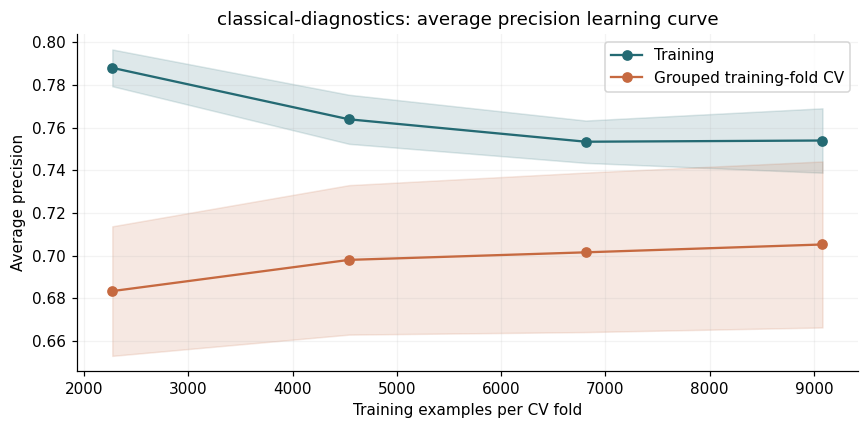

,feature,mean_ap_decrease,std_ap_decrease
8,log_children_5_17,0.000000,0.000000
7,age_band,0.002404,0.000956
2,HL4,0.003552,0.001826
1,HH52,0.003953,0.000588
3,HH6,0.016611,0.003803
0,CB3,0.028692,0.002169
6,WINDEX5,0.103276,0.008038
4,HH7,0.136578,0.001167
5,MELEVEL,0.171523,0.010705


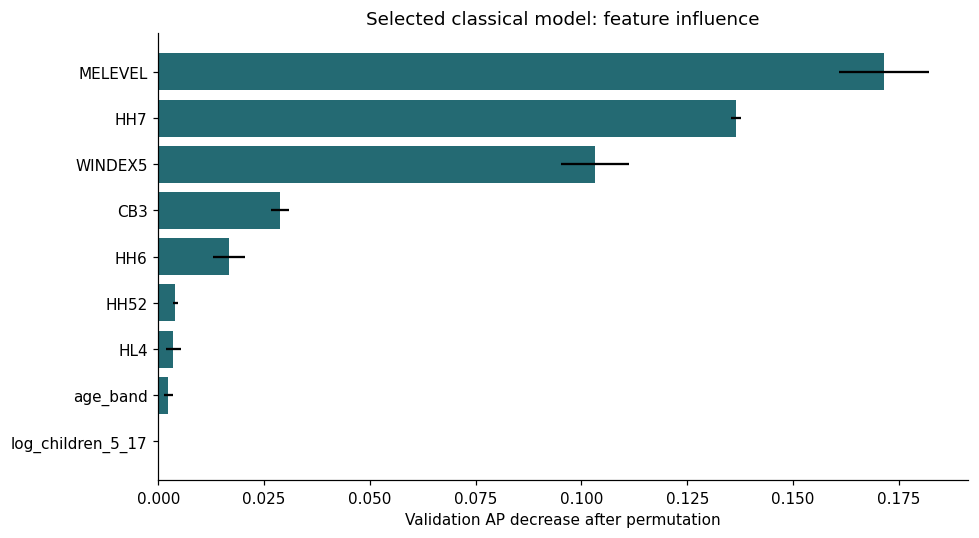

,family,experiment,threshold,variable,group,n,positive_n,negative_n,false_negatives,recall,false_positive_rate
0,classical,E10,0.35,HL4,FEMALE,2190,592,1598,180,0.695946,0.132040
1,classical,E10,0.35,HL4,MALE,2256,591,1665,202,0.658206,0.123123
2,classical,E10,0.35,HH6,RURAL,3008,951,2057,247,0.740273,0.159456
3,classical,E10,0.35,HH6,URBAN,1438,232,1206,135,0.418103,0.072968
4,classical,E10,0.35,target_origin,derived: never attended,859,859,0,166,0.806752,NaN
5,classical,E10,0.35,target_origin,direct CB7,3587,324,3263,216,0.333333,0.127490
6,neural,E06,0.38,HL4,FEMALE,2190,592,1598,181,0.694257,0.138924
7,neural,E06,0.38,HL4,MALE,2256,591,1665,203,0.656514,0.136336
8,neural,E06,0.38,HH6,RURAL,3008,951,2057,244,0.743428,0.175498
9,neural,E06,0.38,HH6,URBAN,1438,232,1206,140,0.396552,0.072968


In [31]:
chosen = selected['classical']; exp = chosen['experiment']
frames = experiment_frames(chosen['variant'])
best_pipeline = fitted_models[exp]['model']
with start_tracked_run('classical-diagnostics','diagnostics',chosen) as run:
    sizes,train_scores,val_scores = learning_curve(clone(best_pipeline),frames['train'],y_train,
        groups=train_groups,cv=cv,train_sizes=[.25,.5,.75,1.],scoring='average_precision',
        shuffle=True,random_state=SEED,n_jobs=1,error_score='raise')
    log_learning_curve(run,sizes,train_scores,val_scores,score_name='Average precision',metric_key='average_precision')
    pd.DataFrame({'train_size':sizes,'train_mean':train_scores.mean(axis=1),
                  'train_std':train_scores.std(axis=1),'cv_mean':val_scores.mean(axis=1),
                  'cv_std':val_scores.std(axis=1)}).to_csv(RESULTS/'classical_learning_curve.csv',index=False)
    importance = permutation_importance(best_pipeline,frames['validation'],parts['validation'][1],
                   scoring='average_precision',n_repeats=5,random_state=SEED,n_jobs=1)
    importance_table = pd.DataFrame({'feature':frames['validation'].columns,
        'mean_ap_decrease':importance.importances_mean,'std_ap_decrease':importance.importances_std}).sort_values('mean_ap_decrease')
    display(importance_table)
    importance_table.to_csv(RESULTS/'validation_permutation_importance.csv',index=False)
    run.log({'interpretation/permutation_importance':importance_table})
    fig,ax = plt.subplots(figsize=(9,5))
    ax.barh(importance_table['feature'],importance_table['mean_ap_decrease'],
            xerr=importance_table['std_ap_decrease'],color='#246a73')
    ax.set(xlabel='Validation AP decrease after permutation',title='Selected classical model: feature influence')
    fig.tight_layout(); run.log({'interpretation/importance_chart':fig}); plt.show()
plt.close('all')

# Aggregate error analysis for the selected models; no row-level data is exported.
validation_subgroups = []
truth = parts['validation'][1].to_numpy()
validation_index = parts['validation'][0].index
for family,choice in selected.items():
    predicted = validation_probabilities[choice['experiment']]>=choice['threshold']
    for column in ['HL4','HH6','target_origin']:
        values = cohort.loc[validation_index,column]
        names = values.map(lambda value:value_labels[column].get(value,str(value))) if column in value_labels else values.astype(str)
        for group_name in sorted(names.unique()):
            mask = names.eq(group_name).to_numpy()
            yt,yp = truth[mask],predicted[mask]
            positives,negatives = int(yt.sum()),int((yt==0).sum())
            validation_subgroups.append({'family':family,'experiment':choice['experiment'],
                'threshold':choice['threshold'],'variable':column,'group':group_name,'n':len(yt),
                'positive_n':positives,'negative_n':negatives,
                'false_negatives':int(((yt==1)&(~yp)).sum()),
                'recall':float(yp[yt==1].mean()) if positives else np.nan,
                'false_positive_rate':float(yp[yt==0].mean()) if negatives else np.nan})
validation_subgroups = pd.DataFrame(validation_subgroups)
display(validation_subgroups)
validation_subgroups.to_csv(RESULTS/'validation_subgroups.csv',index=False)
with start_tracked_run('validation-error-analysis','diagnostics',{'selected':selected,'split':'validation'}) as run:
    run.log({'errors/subgroups':validation_subgroups})


## 19. Optional test evaluation

The cell below evaluates the selected classical and neural models only when `RUN_FINAL_TEST=True`. It remains disabled. Earlier project work inspected a test partition, so later reuse must disclose that history.


In [32]:
RUN_FINAL_TEST = False  # Existing test results have already been inspected.
if RUN_FINAL_TEST:
    test_rows,subgroup_rows = [],[]
    test_predictions = {}
    test_truth = parts['test'][1].to_numpy()
    test_idx = parts['test'][0].index
    for family,choice in selected.items():
        exp,variant,threshold = choice['experiment'],choice['variant'],choice['threshold']
        if family=='classical':
            model = fitted_models[exp]['model']
            p = model.predict_proba(experiment_frames(variant)['test'])[:,1]
            joblib.dump(model,MODEL_DIR/'best_classical.joblib')
            restored = joblib.load(MODEL_DIR/'best_classical.joblib')
            assert np.allclose(p,restored.predict_proba(experiment_frames(variant)['test'])[:,1])
        else:
            model = tf.keras.models.load_model(fitted_models[exp]['model_path'])
            p = model.predict(make_dataset(representations[variant]['matrices']['test']),verbose=0).ravel()
            model.save(MODEL_DIR/'best_neural.keras')
            model.save_weights(MODEL_DIR/'best_neural.weights.h5')
            joblib.dump(representations[variant]['preprocessor'],MODEL_DIR/'best_neural_preprocessor.joblib')
            restored = tf.keras.models.load_model(MODEL_DIR/'best_neural.keras')
            assert np.allclose(p,restored.predict(make_dataset(representations[variant]['matrices']['test']),verbose=0).ravel(),atol=1e-6)
        test_predictions[family] = p
        with start_tracked_run(f'final-{family}','final-test',choice) as run:
            metrics = log_binary_evaluation(run,test_truth,p,split='test',threshold=threshold)
            metrics['balanced_accuracy'] = balanced_accuracy_score(test_truth,p>=threshold)
            metrics['log_loss'] = log_loss(test_truth,p,labels=[0,1])
            weight = cohort.loc[test_idx,'FSWEIGHT'].to_numpy(dtype=float)
            ok = np.isfinite(weight)&(weight>0)
            weighted = {'average_precision':average_precision_score(test_truth[ok],p[ok],sample_weight=weight[ok]),
                        'roc_auc':roc_auc_score(test_truth[ok],p[ok],sample_weight=weight[ok]),
                        'recall':recall_score(test_truth[ok],p[ok]>=threshold,sample_weight=weight[ok],zero_division=0),
                        'f1':f1_score(test_truth[ok],p[ok]>=threshold,sample_weight=weight[ok],zero_division=0)}
            run.log({**{f'test/{k}':float(v) for k,v in metrics.items()},
                     **{f'test_weighted/{k}':float(v) for k,v in weighted.items()}})
            test_rows.append({'family':family,'experiment':exp,'tensorboard_run_id':run.id,**metrics,
                              **{f'weighted_{k}':v for k,v in weighted.items()}})
            subgroup_start = len(subgroup_rows)
            for column in ['HL4','HH6','target_origin']:
                s = cohort.loc[test_idx,column].astype(str)
                for group_name in sorted(s.unique()):
                    mask = s.eq(group_name).to_numpy()
                    yt,yp = test_truth[mask],p[mask]>=threshold
                    positives,negatives = int(yt.sum()),int((yt==0).sum())
                    subgroup_rows.append({'family':family,'variable':column,'group':group_name,
                        'n':len(yt),'positive_n':positives,'negative_n':negatives,
                        'recall':float(yp[yt==1].mean()) if positives else np.nan,
                        'false_positive_rate':float(yp[yt==0].mean()) if negatives else np.nan,
                        'accuracy':float((yp==yt).mean())})
            run.log({'test/subgroups':pd.DataFrame(subgroup_rows[subgroup_start:])})
        plt.close('all')
    test_table,subgroup_table = pd.DataFrame(test_rows),pd.DataFrame(subgroup_rows)
    display(test_table); display(subgroup_table)
    test_table.to_csv(RESULTS/'final_test_metrics.csv',index=False)
    subgroup_table.to_csv(RESULTS/'test_subgroups.csv',index=False)
else:
    print('Test evaluation skipped: this extension uses training CV and validation only.')


Test evaluation skipped: this extension uses training CV and validation only.


## 20. Package the evidence

The cell below packages model files, metrics, figures and TensorBoard logs into one ZIP, excluding the raw survey. Viewing results does not require downloading it. Save the executed notebook to retain its visible figures.


In [33]:
manifest = {'source_sha256':source_hash,'seed':SEED,'selected_models':selected,
            'accuracy_selection':accuracy_choice,'completed_experiments':len(experiment_rows),
            'target':{'0':'attended','1':'did not attend'},'raw_feature_columns':features,
            'enhanced_recipe':{'age_band':'pd.cut(CB3,[4,9,14,17],labels=[5–9,10–14,15–17])',
                               'log_children_5_17':'numpy.log1p(HH52)'},
            'input_contract':'Use clean_feature and add_features from this notebook before prediction.',
            'training_rows':len(y_train),'validation_rows':len(parts['validation'][1]),
            'test_rows':len(parts['test'][1]),'versions':versions,'tracking':'TensorBoard',
            'selection_protocol':'Highest validation AP per family across E01–E10; thresholds maximize validation F1',
            'saved_model_roundtrip_verified_on':'validation samples',
            'status':'training completed; test evaluated' if RUN_FINAL_TEST else 'training completed; test evaluation skipped',
            'test_previously_inspected':True,
            'runs':{row['experiment']:row['tensorboard_run_id'] for row in experiment_rows}}
(MODEL_DIR/'model_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
(RESULTS/'requirements.txt').write_text('\n'.join(f'{p}=={v}' for p,v in versions.items())+'\n',encoding='utf-8')
import subprocess, sys
environment = {'python':sys.version,'platform':platform.platform(),'packages':versions}
(RESULTS/'runtime_environment.json').write_text(json.dumps(environment,indent=2),encoding='utf-8')
(RESULTS/'environment_freeze.txt').write_text(
    subprocess.check_output([sys.executable,'-m','pip','freeze'],text=True),encoding='utf-8')
(RESULTS/'README.md').write_text('\n'.join([
    '# Nigeria MICS 2021 — Colab and TensorBoard',
    'Source: https://microdata.worldbank.org/catalog/5959 ; one input file: fs.sav.',
    'Positive class: current reported nonattendance. Splits are grouped by PSU.',
    'Ten separate experiments compare logistic regression, forests, boosting and TensorFlow/Keras MLPs. Diagnostic CV curves at selected settings are not nested selection estimates.',
    'experiments.csv links each model and metrics to its tensorboard_run_id.',
    'Ten-run accuracy comparison uses threshold 0.5. Final selection uses validation AP per family across E01–E10; thresholds use validation F1.',
    'Test evaluation is disabled by default; previous inspection is disclosed in the manifest.',
    'Scalars: validation metrics, classical CV accuracy by training size, neural metrics by epoch. Images: per-run and combined comparisons. HParams: all completed experiments.',
    'Text: settings, search candidates and comparison tables. E05–E07 also contain Keras epoch events.',
    'After extracting this ZIP, run: tensorboard --logdir tensorboard',
    'Classical models include preprocessing; neural models need the matching saved preprocessor.',
    'Individual models are saved under results/runs. Selected best_* models and neural weights are saved before optional test evaluation.',
    'This bundle excludes raw survey data and private row-level arrays.',
]),encoding='utf-8')
audit.update({'versions':versions,'stage':'model training completed','selected':selected,'tracking':'TensorBoard'})
(ARTIFACTS/'audit.json').write_text(json.dumps(audit,indent=2),encoding='utf-8')
bundle = WORK/'experiment_evidence_tensorboard.zip'
with zipfile.ZipFile(bundle,'w',compression=zipfile.ZIP_DEFLATED) as archive:
    for directory in [ARTIFACTS,MODEL_DIR,RESULTS,TENSORBOARD_ROOT]:
        for file in directory.rglob('*'):
            if file.is_file(): archive.write(file,file.relative_to(WORK))
print('Completed experiments:',len(experiment_rows))
print('Evidence bundle:',bundle)


Completed experiments: 10
Evidence bundle: /content/mics_project/20261017T214243-e13712d9/experiment_evidence_tensorboard.zip


### Optional backup download

Set `DOWNLOAD_EVIDENCE=True` only when you want a local backup. Colab runtime files are temporary; the executed notebook preserves inline figures, while the ZIP also preserves models and TensorBoard logs.


In [34]:
DOWNLOAD_EVIDENCE = False
if DOWNLOAD_EVIDENCE:
    from google.colab import files
    files.download(str(bundle))
else:
    print('All results are visible above. The evidence ZIP is ready if a backup is needed.')


All results are visible above. The evidence ZIP is ready if a backup is needed.


Here is the tensorboard for every run made

In [37]:
%load_ext tensorboard
%tensorboard --logdir {TENSORBOARD_ROOT}

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 2521), started 0:44:23 ago. (Use '!kill 2521' to kill it.)

<IPython.core.display.Javascript object>

## 21. Current execution summary

The cell below summarizes this execution. Use these results in the report, alongside the target reconstruction, cluster sampling and prior test-inspection limitations.


In [35]:
# ap_winner = experiment_table.sort_values(['validation_average_precision','experiment'],ascending=[False,True]).iloc[0]
# recall_winner = experiment_table.sort_values(['validation_recall','experiment'],ascending=[False,True]).iloc[0]
# derived = int(cohort['target_origin'].ne('direct CB7').sum())
# display(Markdown(
#     f'**{len(experiment_table)} experiments completed.** Accuracy leader: '
#     f'{accuracy_choice["experiment"]} ({accuracy_choice["validation_accuracy"]:.2%} at threshold 0.50). '
#     f'AP leader: {ap_winner["experiment"]} ({ap_winner["validation_average_precision"]:.4f}). '
#     f'Recall leader at 0.50: {recall_winner["experiment"]} ({recall_winner["validation_recall"]:.2%}).\n\n'
#     f'**Selected models:** {selected["classical"]["experiment"]} (classical) and '
#     f'{selected["neural"]["experiment"]} (neural), selected by validation AP. '
#     f'Their F1-tuned thresholds are {selected["classical"]["threshold"]:.2f} and '
#     f'{selected["neural"]["threshold"]:.2f}.\n\n'
#     f'**Limits:** {derived:,} labels were reconstructed from never-attended responses; '
#     'these models classify reported attendance and do not establish causes or predict future dropout. '
#     'Overall results are unweighted sample metrics. A test partition was inspected in earlier project work; '
#     + ('this execution also evaluated it, so it is not a fresh independent holdout.' if RUN_FINAL_TEST else
#        'this execution did not evaluate it. Validation scores are not final test accuracy.')))


**10 experiments completed.** Accuracy leader: E06 (82.82% at threshold 0.50). AP leader: E10 (0.7163). Recall leader at 0.50: E05 (58.50%).

**Selected models:** E10 (classical) and E06 (neural), selected by validation AP. Their F1-tuned thresholds are 0.35 and 0.38.

**Limits:** 4,435 labels were reconstructed from never-attended responses; these models classify reported attendance and do not establish causes or predict future dropout. Overall results are unweighted sample metrics. A test partition was inspected in earlier project work; this execution did not evaluate it. Validation scores are not final test accuracy.